# Task 09 — Regulatory obligations copilot: which article, from when, and as of which date

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [EU AI Act, related EU digital acts and US Federal Register AI documents](https://www.kaggle.com/datasets/sadiqguru/ai-regulation-eu-us) — 12 EU acts, article by article, with dates and amendment links (CC BY 4.0)
**Task family:** retrieval without an LLM, knowledge graph (RDF + SHACL), as-of question answering · **Companion task:** `04_erp_document_rag.ipynb` (retrieval without an LLM)

---

## The task card

> **Board question.** *Our compliance lead has to say, for every AI system we build or buy, which EU obligations apply, from when, and which article says so. In July 2026 the Digital Omnibus moved the high-risk dates by up to 16 months. Can a copilot answer with a citation that was valid on the date asked — and never quote a recital or a superseded date?*

**Business context.** Firms that build or buy AI increasingly keep an AI register, and compliance must say which duties attach to each entry. The legacy estate is a GRC tool, PDFs saved from EUR-Lex, and counsel's memos. The copilot is Session 01's *human-in-the-loop decision support* pattern: it drafts a cited answer, a person signs it off. The difficulty is time: provisions apply from different dates and amending acts rewrite them, so the correct answer depends on the date asked.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **knowledge-graph pipeline**, packaged and validated with SHACL;
2. the given **retrieval pipeline** with query understanding and an as-of filter, packaged and reproducible, gated in CI;
3. a **generation step** returning `{obligations[], articles[], applies_from}`, every claim checked against the graph;
4. a one-page **recommendation for the compliance lead**: what the copilot answers, escalates, and costs.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Copilot beside the GRC tool; human sign-off; its own AI Act position |
| 2 · MLOps | Golden-set gate in CI; graph build and SHACL as a stage; re-index on amendment |
| 3 · Semantic layer | Graph from competency questions; prose into rules; SHACL (S07–09) |
| 4 · LLM/RAG | Query understanding, as-of Graph-RAG, chunking budget, claim verification (S10–11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The baseline runs **without any LLM**, so retrieval and date logic are measured before generation hides them. Four traps are left in, measured and flagged ⚠.

**Honesty note.** The texts are **real** EU legislation as held in the dataset (retrieved 13 Oct 2026), consistent with public summaries of Regulation (EU) 2026/1744 (the Digital Omnibus on AI) as of 26 Oct 2026; check EUR-Lex before teaching. The curated dates were compiled by the dataset author from Article 113 of the AI Act. Mapping dates to articles, extracting obligations and scoping tiers are this notebook's reading; nothing here is legal advice.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at twelve acts and one calendar | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | The knowledge graph and its shapes, retrieval over a golden set, as-of answers and the operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The index after the law moves, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the drift your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_corpus` (Section 1); `version_in_force`, `applies_from`, `extract_obligations`, `build_kg`, `shacl_report` and `sparql` (Section 3); `lookup_q`, `understand`, `in_force_mask`, `retrieve`, `rrf` and `score` (Section 4); `date_for`, `answer_system` and `verify_claim` (Section 5).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 2,518 provision rows (2,015 distinct) from 12 acts; a graph of 22,620 triples (109 obligation, 304 applicability and 46 amendment nodes) that conforms to the six shapes; 405 golden questions; full pipeline recall@1 0.81 on article lookups and 1.00 on as-of dates (recall@5 0.96 and 1.00); a 4,000-token budget gives k = 8 at recall 0.991 and about €0.013 an answer.
- **Runtime:** under a minute on a laptop (35 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, re, time, json, warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, precision_score, recall_score, accuracy_score
import rdflib
from rdflib import Graph, Namespace, Literal
from rdflib.namespace import RDF, XSD
import pyshacl

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 70)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "sadiqguru/ai-regulation-eu-us"
AI_ACT, OMNIBUS = "32024R1689", "32026R1744"   # CELEX numbers: the AI Act and the Digital Omnibus on AI that amends it
SNAPSHOT = pd.Timestamp("2026-10-13")           # the dataset's retrieval date: "today" for this knowledge base
AS_OF_DATES = [pd.Timestamp("2025-03-01"), pd.Timestamp("2026-07-01"), SNAPSHOT]   # golden as-of dates: early, just before the Omnibus, today
TIMELINE_START, TIMELINE_END = pd.Timestamp("2024-08-01"), pd.Timestamp("2028-12-31")
CLASSIFIER_SPLIT = pd.Timestamp("2023-01-01")   # train on acts published before, test on acts published from this date
N_LOOKUP_PER_ACT = 12         # article-lookup questions sampled per act (all "boilerplate" headings are added on top)
N_DATE_PER_RULE = 4           # as-of questions per application rule and as-of date
K = 5                         # retrieval depth reported
CONTEXT_BUDGET_TOKENS = 4000  # assumption: context the generation step may receive per answer (Stretch S1); vary it in task C3
PASSAGE_CAP_WORDS = 400       # chunking rule tested in Section 5: passages longer than this are cut
TOKENS_PER_WORD = 1.35        # English legal text, typical BPE tokenisers
PROMPT_OVERHEAD_TOKENS, ANSWER_TOKENS = 600, 400
EUR_PER_M_INPUT, EUR_PER_M_OUTPUT = 2.50, 10.00   # assumed model prices (task C3 replaces them with your provider's)
QUESTIONS_PER_MONTH = 2000    # assumed load: a compliance team of ~15 people

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "ai_regulation", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
rng = np.random.default_rng(SEED)
T_START = time.time()
import sklearn
print(f"pandas {pd.__version__} · scikit-learn {sklearn.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_corpus`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `sadiqguru/ai-regulation-eu-us`, retrieved 13 Oct 2026 from EUR-Lex, Cellar metadata and the US Federal Register |
| **Licence** | CC BY 4.0 (attribute the dataset author); EU texts are reusable under Commission Decision 2011/833/EU |
| **Provenance** | Real legislation, as held in the dataset: the AI Act, the Digital Omnibus on AI that amends it, and ten related digital acts (Section 2); seven held *as published* and *consolidated* |
| **Size** | 2,518 provision rows (2,015 distinct provisions; 1,168 article, 1,295 recital, 55 annex rows), 0.67 M words; 82 date rows; 5 amendment rows; plus 1,434 US documents |
| **Files** | Used: `eu_provisions`, `eu_acts`, `eu_act_dates`, `eu_amendments` (Parquet; CSV also ships). Not used: `instruments`, `us_*` |
| **Schema (provisions)** | `celex`, `text_version`, `provision_type` (article / recital / annex), `provision_number`, `heading`, `chapter`, `section`, `text` |
| **Label** | None. Headings, structure and the 13 curated date rows (`source = art_113_curated`) generate the golden set |
| **Window used here** | All EU rows; golden as-of dates 1 Mar 2025, 1 Jul 2026 and 13 Oct 2026 (the snapshot); drift timeline Aug 2024 – Dec 2028 |
| **PII** | None in the EU texts (checked on load); the US tables, which name officials, are not loaded |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Two texts of one act.** The AI Act as published is the law from 1 Aug 2024 to 26 Jul 2026; the consolidated text, with the Omnibus, from 27 Jul 2026. Consolidated texts have no recitals. (Trap 2.)
2. ⚠ **Dates of application are curated for the AI Act only.** Use the 13 `art_113_curated` rows, as the dataset says; the 69 `cellar_metadata` rows have no scope and still list the superseded 2 Aug 2027. (Trap 2.)
3. ⚠ **Half the rows are recitals.** They do not bind, yet read like obligations ("providers should …"). (Trap 1.)
4. **Amendment links are act-level**; which provisions changed must be parsed from the Omnibus.
5. **Extraction artefacts**: duplicated nested points, repeated quotations, shifting footnote markers.
6. **Boilerplate and duplicates** across acts and versions. (Trap 4.)
7. **No questions ship.** The golden set is generated from headings and date rows: exact, and leaky. (Trap 3.)

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_corpus() -> pd.DataFrame:
    '''EU provisions with their act's metadata, cleaned once and cached as parquet (the US tables are not used here).'''
    cache = PROCESSED / "09_eu_provisions.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    prov = pd.read_parquet(get_raw("eu_provisions.parquet"))
    for c in ["heading", "chapter", "chapter_title", "section", "section_title", "consolidated_celex"]:
        prov[c] = prov[c].fillna("").astype(str)
    prov["heading"] = prov.heading.str.strip(" `'’")          # stray quote marks from the HTML extraction ("Subject matter`")
    prov.to_parquet(cache)
    return prov

prov = load_corpus()
acts = pd.read_parquet(get_raw("eu_acts.parquet"))
dates = pd.read_parquet(get_raw("eu_act_dates.parquet"))
amend = pd.read_parquet(get_raw("eu_amendments.parquet"))
short = acts.set_index("celex").short_title
prov["act"] = prov.celex.map(short)
prov["binding"] = prov.provision_type.isin(["article", "annex"])   # recitals explain; only articles and annexes bind

# ---- governance on load: legislation carries no personal data, but check rather than assume ----
n_email = int(prov.text.str.contains(r"[\w.+-]+@[\w-]+\.[\w.]+", regex=True).sum())
assert n_email == 0, "personal contact data found in the corpus: pseudonymise before indexing"

us = pd.read_parquet(get_raw("us_documents.parquet"), columns=["document_type", "publication_date"])   # metadata only, for the dataset card
print(f"US Federal Register documents (not used below): {len(us):,}, {us.publication_date.min():%b %Y} – {us.publication_date.max():%b %Y}, "
      f"{us.document_type.value_counts().to_dict()}")
print(f"{len(prov):,} provisions · {prov.celex.nunique()} acts · {prov.word_count.sum()/1e6:.2f} M words · "
      f"{prov.provision_type.value_counts().to_dict()} · {(prov.text_version == 'consolidated').sum()} rows from consolidated texts · "
      f"e-mail addresses found: {n_email} · {prov.memory_usage(deep=True).sum()/1e6:.0f} MB")

US Federal Register documents (not used below): 1,434, Apr 2016 – Oct 2026, {'notice': 954, 'rule': 215, 'proposed_rule': 196, 'presidential_document': 69}
2,518 provisions · 12 acts · 0.67 M words · {'recital': 1295, 'article': 1168, 'annex': 55} · 535 rows from consolidated texts · e-mail addresses found: 0 · 5 MB


## 2 · First look: twelve acts, two texts of the AI Act, one calendar

*Part A · Explore · read; the two texts and the moved calendar are what your index must track.*

First questions: which acts, how much binds, and what the calendar looks like.

In [3]:
uniq = prov.drop_duplicates(["celex", "provision_type", "provision_number"])
overview = uniq.groupby(["act", "provision_type"]).size().unstack(fill_value=0)[["article", "annex", "recital"]]
overview["texts held"] = prov.groupby("act").text_version.agg(lambda s: " + ".join(sorted(set(s), key=["as_published", "consolidated"].index)))
overview = overview.join(acts.set_index("short_title")[["act_type", "year", "ai_relevance"]]).sort_values("year")
overview["words"] = prov.groupby("act").word_count.sum()
display(overview)
print(f"{len(uniq):,} distinct provisions behind the {len(prov):,} rows; {(prov.provision_type == 'recital').mean():.0%} of rows are recitals")

,article,annex,recital,texts held,act_type,year,ai_relevance,words
act,,,,,,,,
ePrivacy Directive,23,0,0,consolidated,directive,2002,related,4773
GDPR,99,0,173,as_published + consolidated,regulation,2016,related,82674
Cybersecurity Act,71,1,110,as_published + consolidated,regulation,2019,related,48616
Digital Services Act,93,0,156,as_published,regulation,2022,related,61941
Digital Markets Act,54,1,109,as_published + consolidated,regulation,2022,related,59365
NIS2 Directive,46,3,144,as_published + consolidated,directive,2022,related,60706
Data Governance Act,38,0,63,as_published,regulation,2022,related,26863
Data Act,50,0,119,as_published,regulation,2023,related,43877
Cyber Resilience Act,71,8,130,as_published + consolidated,regulation,2024,related,81644


2,015 distinct provisions behind the 2,518 rows; 51% of rows are recitals


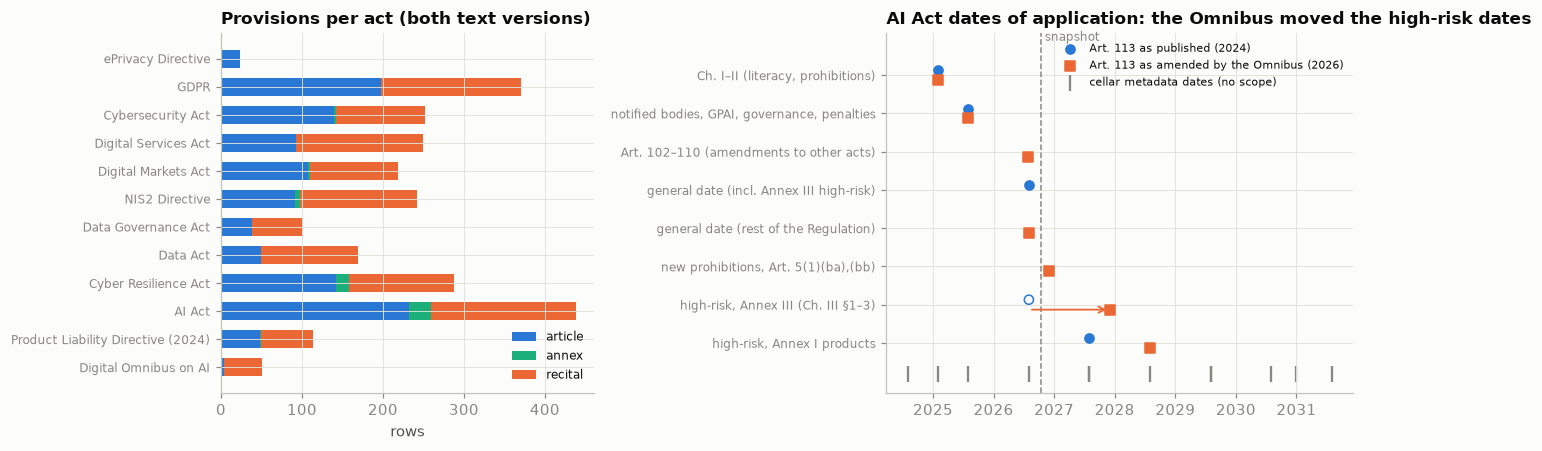

high-risk (Annex III) obligations moved 16 months (2026-08-02 → 2027-12-02); Annex I products 12 months (2027-08-02 → 2028-08-02)
date rows: 82 ({'cellar_metadata': 69, 'art_113_curated': 13}); curated rows exist only for the AI Act


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
cnt = prov.groupby(["act", "provision_type"]).size().unstack(fill_value=0).loc[overview.index]
left = np.zeros(len(cnt))
for t, color in zip(["article", "annex", "recital"], [SERIES[0], SERIES[2], SERIES[1]]):
    ax.barh(cnt.index, cnt[t], left=left, color=color, height=0.65, label=t)
    left += cnt[t].values
ax.invert_yaxis(); ax.legend(fontsize=8, loc="lower right"); ax.tick_params(axis="y", labelsize=8)
ax.set_title("Provisions per act (both text versions)"); ax.set_xlabel("rows")

ax = axes[1]
cur = dates[(dates.source == "art_113_curated") & (dates.date_type == "application")].copy()
cur["version"] = np.where(cur.text_version == "as_published", "as_published", "consolidated")
labels = {"32024R1689|3": "Ch. I–II (literacy, prohibitions)", "32024R1689|4": "Ch. I–II (literacy, prohibitions)",
          "32024R1689|5": "notified bodies, GPAI, governance, penalties", "32024R1689|6": "notified bodies, GPAI, governance, penalties",
          "32024R1689|7": "Art. 102–110 (amendments to other acts)", "32024R1689|8": "general date (incl. Annex III high-risk)",
          "32024R1689|9": "general date (rest of the Regulation)", "32024R1689|10": "new prohibitions, Art. 5(1)(ba),(bb)",
          "32024R1689|11": "high-risk, Annex I products", "32024R1689|12": "high-risk, Annex III (Ch. III §1–3)",
          "32024R1689|13": "high-risk, Annex I products"}
cur["label"] = cur.date_id.map(labels)
rows_ = list(dict.fromkeys(["Ch. I–II (literacy, prohibitions)", "notified bodies, GPAI, governance, penalties", "Art. 102–110 (amendments to other acts)",
                            "general date (incl. Annex III high-risk)", "general date (rest of the Regulation)", "new prohibitions, Art. 5(1)(ba),(bb)",
                            "high-risk, Annex III (Ch. III §1–3)", "high-risk, Annex I products"]))
ypos = {l: i for i, l in enumerate(rows_)}
for v, color, dy, mk in [("as_published", SERIES[0], -0.13, "o"), ("consolidated", SERIES[1], 0.13, "s")]:
    d = cur[cur.version == v]
    ax.scatter(d.date, [ypos[l] + dy for l in d.label], color=color, s=36, marker=mk, label=f"Art. 113 as {'published (2024)' if v == 'as_published' else 'amended by the Omnibus (2026)'}", zorder=3)
cellar = dates[(dates.celex == AI_ACT) & (dates.source == "cellar_metadata") & (dates.date_type.isin(["entry_into_force", "deadline"]))]
ax.scatter(cellar.date, [len(rows_) - 0.2] * len(cellar), marker="|", s=120, color=MUTED, label="cellar metadata dates (no scope)")
hr = cur[cur.label == "high-risk, Annex III (Ch. III §1–3)"].date.iloc[0]
ax.scatter([pd.Timestamp("2026-08-02")], [ypos["high-risk, Annex III (Ch. III §1–3)"] - 0.13], s=36, facecolors="none", edgecolors=SERIES[0], zorder=3)   # as published: the general date
ax.annotate("", xy=(hr, ypos["high-risk, Annex III (Ch. III §1–3)"] + 0.13), xytext=(pd.Timestamp("2026-08-02"), ypos["high-risk, Annex III (Ch. III §1–3)"] + 0.13),
            arrowprops=dict(arrowstyle="->", color=SERIES[1], lw=1.2))
ax.axvline(SNAPSHOT, color=MUTED, ls="--", lw=1); ax.text(SNAPSHOT, -0.9, " snapshot", color=MUTED, fontsize=8)
ax.set_yticks(range(len(rows_))); ax.set_yticklabels(rows_, fontsize=8); ax.set_ylim(len(rows_) + 0.3, -1.1)
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y")); ax.legend(fontsize=7, loc="upper right")
ax.set_title("AI Act dates of application: the Omnibus moved the high-risk dates")
plt.tight_layout(); plt.show()

months_moved = lambda a, b: (b.year - a.year) * 12 + b.month - a.month
d_old_iii, d_new_iii = pd.Timestamp("2026-08-02"), cur.loc[cur.date_id == "32024R1689|12", "date"].iloc[0]
d_old_i, d_new_i = cur.loc[cur.date_id == "32024R1689|11", "date"].iloc[0], cur.loc[cur.date_id == "32024R1689|13", "date"].iloc[0]
print(f"high-risk (Annex III) obligations moved {months_moved(d_old_iii, d_new_iii)} months ({d_old_iii.date()} → {d_new_iii.date()}); "
      f"Annex I products {months_moved(d_old_i, d_new_i)} months ({d_old_i.date()} → {d_new_i.date()})")
print(f"date rows: {len(dates)} ({dates.source.value_counts().to_dict()}); curated rows exist only for the AI Act")

In [5]:
# Data-quality checks a CI stage would run (Session 05) before anything is indexed
dup = prov[prov.duplicated("text", keep=False)]
same_article = dup.groupby("text").apply(lambda g: g[["celex", "provision_type", "provision_number"]].drop_duplicates().shape[0] == 1, include_groups=False)
def repeated_clause(t):
    cl = [c.strip() for c in re.split(r"[;\n]|(?<=\.)\s", t) if len(c.strip()) >= 60]
    return len(cl) != len(set(cl))
rep = prov[prov.binding].groupby("text_version").text.apply(lambda s: s.map(repeated_clause).mean())
print(f"{len(dup):,} rows share their exact text with another row ({dup.text.nunique()} distinct texts); "
      f"{same_article.mean():.0%} of those groups are the same article in two text versions")
print("share of binding provisions with a clause repeated verbatim (extraction artefact):", rep.round(3).to_dict())

737 rows share their exact text with another row (365 distinct texts); 99% of those groups are the same article in two text versions
share of binding provisions with a clause repeated verbatim (extraction artefact): {'as_published': 0.086, 'consolidated': 0.013}


The AI Act dominates (148 k words over two texts). The calendar is why this notebook exists: Article 113 gives four dates of application as published and seven after the Omnibus, which moved high-risk obligations back 16 months (Annex III) and 12 months (Annex I). For retrieval: 99 % of duplicated texts are one article held twice; 8.6 % of published binding provisions repeat a clause.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The knowledge layer: versions, dates, amendments and obligations as a graph

*Part B · Given model · package `build_kg`, `applies_from` and `extract_obligations` unchanged; SHACL becomes a CI stage (C4).*

Four competency questions shape the graph (Session 07): *which text was in force on a date*, *what changed and how*, *what binds this actor and from when*, *which texts are stale*. Two decisions follow:

- **Text versions carry a validity interval**, each superseded by the next.
- **Dates of application are rules.** Each curated row's prose scope becomes a hand-written selector over chapter, section and article, never earlier than the text existed; assertions check every row has one and every date appears in Article 113 of its version.

In [6]:
eif = acts.set_index("celex").first_entry_into_force_date
ver = prov.groupby(["celex", "text_version"]).agg(consolidated_celex=("consolidated_celex", "first"), provisions=("provision_id", "size")).reset_index()
ver["valid_from"] = [eif[c] if v == "as_published" else max(pd.Timestamp(cc[-8:]), eif[c])
                     for c, v, cc in zip(ver.celex, ver.text_version, ver.consolidated_celex)]
ver = ver.sort_values(["celex", "valid_from", "text_version"])
ver["valid_to"] = ver.groupby("celex").valid_from.shift(-1)          # a version is superseded by the next one
ver_valid = {(r.celex, r.text_version): (r.valid_from, r.valid_to) for r in ver.itertuples()}

def version_in_force(celex, d):
    v = ver[(ver.celex == celex) & (ver.valid_from <= d) & (ver.valid_to.isna() | (ver.valid_to > d))]
    return v.text_version.iloc[-1] if len(v) else None

# ---- application rules: each curated row's scope (prose) translated into a selector over the act's structure ----
S13 = {"1", "2", "3"}
n_int = lambda n: int(re.match(r"(\d+)", n).group(1)) if re.match(r"\d", n) else -1
early_2025 = lambda a: ((a["chapter"] == "III" and a["section"] == "4") or a["chapter"] in ("V", "VII", "XII") or a["num"] == "78") and a["num"] != "101"
SELECT = {
    "32024R1689|3":  lambda a: a["chapter"] in ("I", "II"),
    "32024R1689|5":  early_2025,
    "32024R1689|11": lambda a: a["chapter"] == "III" and a["section"] in S13 and a["tier"] == "annex_i",
    "32024R1689|8":  lambda a: True,
    "32024R1689|4":  lambda a: a["chapter"] in ("I", "II"),
    "32024R1689|6":  early_2025,
    "32024R1689|7":  lambda a: a["type"] == "article" and 102 <= n_int(a["num"]) <= 110,
    "32024R1689|12": lambda a: a["chapter"] == "III" and a["section"] in S13 and a["tier"] == "annex_iii",
    "32024R1689|13": lambda a: a["chapter"] == "III" and a["section"] in S13 and a["tier"] == "annex_i",
    "32024R1689|9":  lambda a: True,
}
PARAGRAPH_RULES = {"32024R1689|10": "Article 5(1) points (ba), (bb) and 5(1a), (1b): stored as a second date on Article 5"}
ORDER = {"as_published": ["32024R1689|3", "32024R1689|5", "32024R1689|11", "32024R1689|8"],          # most specific first
         "consolidated": ["32024R1689|7", "32024R1689|4", "32024R1689|6", "32024R1689|12", "32024R1689|13", "32024R1689|9"]}
assert set(SELECT) | set(PARAGRAPH_RULES) == set(cur.date_id), "a curated date row has no selector"
rule_date = cur.set_index("date_id").date
art113 = prov[(prov.celex == AI_ACT) & (prov.provision_type == "article") & (prov.provision_number == "113")].set_index("text_version").text
for r in cur.itertuples():                       # consistency: every curated date is written in Article 113 of its own version
    assert f"{r.date.day} {r.date:%B %Y}" in art113[r.version], r.date_id

ai_all = prov[prov.celex == AI_ACT].assign(vf=lambda d: d.text_version.map(lambda v: ver_valid[(AI_ACT, v)][0]))
first_seen = ai_all.groupby(["provision_type", "provision_number"]).vf.min()   # when the provision's text first entered the law

def applies_from(row, tier, version):
    '''Date from which a binding AI Act provision applies under `version`, for a system of `tier`; never before the text existed.'''
    a = {"chapter": row.chapter, "section": row.section, "num": row.provision_number, "type": row.provision_type, "tier": tier}
    for did in ORDER[version]:
        if SELECT[did](a):
            return max(rule_date[did], first_seen[(row.provision_type, row.provision_number)]), did

reissued = ver[(ver.text_version == "consolidated") & (ver.consolidated_celex.str[-8:].map(pd.Timestamp) <= ver.celex.map(eif))].celex.map(short)
print(f"'consolidated' texts dated on or before entry into force (the original re-issued): {sorted(reissued)}")
display(ver[ver.celex.isin([AI_ACT, OMNIBUS, "32019R0881", "32024R2847"])].assign(act=lambda d: d.celex.map(short))
        [["act", "text_version", "consolidated_celex", "provisions", "valid_from", "valid_to"]])
display(cur[["date_id", "date", "version", "status", "scope"]].set_index("date_id"))

'consolidated' texts dated on or before entry into force (the original re-issued): ['Cyber Resilience Act', 'Digital Markets Act', 'GDPR', 'NIS2 Directive', 'Product Liability Directive (2024)']


,act,text_version,consolidated_celex,provisions,valid_from,valid_to
3,Cybersecurity Act,as_published,,180,2019-06-27,2025-02-04
4,Cybersecurity Act,consolidated,02019R0881-20250204,72,2025-02-04,NaT
14,AI Act,as_published,,306,2024-08-01,2026-07-27
15,AI Act,consolidated,02024R1689-20260727,133,2026-07-27,NaT
16,Cyber Resilience Act,as_published,,209,2024-12-10,2024-12-10
17,Cyber Resilience Act,consolidated,02024R2847-20241120,79,2024-12-10,NaT
18,Digital Omnibus on AI,as_published,,51,2026-07-27,NaT


,date,version,status,scope
date_id,,,,
32024R1689|3,2025-02-02,as_published,current,Chapters I and II (general provisions incl. AI literacy; prohibite...
32024R1689|4,2025-02-02,consolidated,current,"Chapters I and II, except Article 5(1) first subparagraph points (..."
32024R1689|5,2025-08-02,as_published,current,"Chapter III Section 4, Chapters V, VII, XII and Article 78 (notifi..."
32024R1689|6,2025-08-02,consolidated,current,"Chapter III Section 4, Chapters V, VII, XII and Article 78, except..."
32024R1689|7,2026-07-27,consolidated,current,Articles 102 to 110 (amendments to other Union acts)
32024R1689|8,2026-08-02,as_published,superseded_for_high_risk,General date of application of the Regulation (incl. high-risk sys...
32024R1689|9,2026-08-02,consolidated,current,General date of application of the Regulation (rest of the Regulat...
32024R1689|10,2026-12-02,consolidated,current,"Article 5(1) first subparagraph points (ba),(bb) and Article 5(1a)..."
32024R1689|11,2027-08-02,as_published,superseded,Article 6(1) and corresponding obligations (high-risk systems that...


Ten selectors cover the application rows; the eleventh, Article 5(1)(ba) and (bb), is a paragraph-level exception stored as a second date on Article 5. The `status` column marks the 2024 high-risk dates superseded.

### Amendments: read the amending act, not the diff

The Omnibus's Article 1 is a numbered list of instructions ("(5) Article 4 is replaced by the following …") that can be parsed; a diff of the two texts is the cheap alternative.

In [7]:
om = prov[(prov.celex == OMNIBUS) & (prov.provision_type == "article") & (prov.provision_number == "1")].text.iloc[0]
starts, k_, pos = [], 1, 0
while (m := re.search(rf"\({k_}\)\s", om[pos:])):          # the amending points are numbered (1), (2), … in order
    starts.append(pos + m.start()); pos += m.end(); k_ += 1
points = []
for i, s in enumerate(starts):
    seg = om[s: starts[i + 1] if i + 1 < len(starts) else len(om)]
    head = seg[:200]
    if re.search(r"the following (?:Article|articles|Annex) (?:is|are) (?:inserted|added)", head):
        targets = sorted(set(t for t in re.findall(r"(Article \d+[a-z]|Annex [IVXL]+)\s+(?=[A-Z])", seg) if re.match(r"Article \d+[a-z]$|Annex XIV$", t)))
        action = "inserted"
    else:
        t0_ = re.search(r"(Article \d+[a-z]?|Annex [IVXL]+)", head).group(1)
        targets, action = [t0_], ("replaced" if re.match(rf"\(\d+\)\s+{re.escape(t0_)} is replaced", head) else "amended")
    points += [{"point": i + 1, "target": t, "action": action} for t in targets]
points = pd.DataFrame(points)
parsed = set(points.target)

# an independent signal: which provisions' text differs between the two versions (whitespace normalised)
norm = lambda s: re.sub(r"\s+", " ", s).strip()
aib = prov[(prov.celex == AI_ACT) & prov.binding]
tv = {v: aib[aib.text_version == v].set_index(["provision_type", "provision_number"]).text.map(norm) for v in ["as_published", "consolidated"]}
lab = lambda t, n: f"{'Article' if t == 'article' else 'Annex'} {n}"
diff_changed = {lab(*i) for i in tv["consolidated"].index if i not in tv["as_published"].index or tv["as_published"][i] != tv["consolidated"][i]}
print(f"Omnibus Article 1: {len(starts)} amending points naming {len(parsed)} AI Act provisions "
      f"({points.drop_duplicates('target').action.value_counts().to_dict()})")
print(f"text differs between versions: {len(diff_changed)} provisions · named by the Omnibus and changed: {len(parsed & diff_changed)} · "
      f"named but unchanged: {len(parsed - diff_changed)} · changed but never named: {len(diff_changed - parsed)}")
ROMAN = {r: i for i, r in enumerate("I II III IV V VI VII VIII IX X XI XII XIII XIV".split(), start=1)}
unnamed = diff_changed - parsed
print("  articles:", ", ".join(sorted((t.split()[1] for t in unnamed if t.startswith("Article")), key=n_int)),
      "\n  annexes: ", ", ".join(sorted((t.split()[1] for t in unnamed if t.startswith("Annex")), key=ROMAN.get)))

Omnibus Article 1: 43 amending points naming 45 AI Act provisions ({'amended': 37, 'inserted': 7, 'replaced': 1})
text differs between versions: 70 provisions · named by the Omnibus and changed: 45 · named but unchanged: 0 · changed but never named: 25
  articles: 7, 13, 41, 53, 59, 66, 68, 78, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110 
  annexes:  III, IV, VII, X, XI, XII


The parse names 45 provisions in 43 points, all of which differ between the texts. The diff also flags 25 the Omnibus never touched (Articles 100–110, Annexes III, IV, X among them): extraction artefacts. Amendment edges therefore come from the amending act, and the diff is a consistency check.

### Obligations: who must do what

An obligation is a clause with an actor as subject of *shall* ("Deployers … shall take appropriate … measures"). Blind spots, on purpose: Section 2 requirements bind the system's provider through Article 16, and public bodies are ignored. The naive extractor accepts any actor near *shall*, *should* or *must*, anywhere.

In [8]:
ACTORS = [("gpai_provider", r"providers? of general-purpose AI models?"), ("authorised_representative", r"authorised representatives?"),
          ("notified_body", r"notified bod(?:y|ies)"), ("deployer", r"deployers?"), ("importer", r"importers?"),
          ("distributor", r"distributors?"), ("provider", r"providers?")]
clauses = lambda t: [c for c in re.split(r"(?<=[.;:])\s+", t) if len(c) > 15]

def extract_obligations(text, modal=r"shall", strict=True):
    '''Clauses in which an actor is the subject of the modal verb. strict=False is the naive version: any actor anywhere near any modal.'''
    found = {}
    for c in clauses(text):
        if not re.search(rf"\b(?:{modal})\b", c):
            continue
        rest = c
        for actor, pat in ACTORS:
            rx = rf"\b{pat}\b[^,;:.]{{0,80}}?\b(?:{modal})\b" if strict else rf"\b{pat}\b"
            if re.search(rx, rest, re.I):
                found.setdefault(actor, []).append(c)
                rest = re.sub(rf"\b{pat}\b", " ", rest, flags=re.I)   # "providers of GPAI models" must not also count as "providers"
    return found

def obligation_table(rows, **kw):
    out = []
    for r in rows.itertuples():
        for actor, cl in extract_obligations(r.text, **kw).items():
            out.append({"pid": r.provision_id, "version": r.text_version, "type": r.provision_type, "num": r.provision_number,
                        "heading": r.heading, "chapter": r.chapter, "section": r.section, "actor": actor, "n": len(cl), "example": cl[0][:150]})
    return pd.DataFrame(out)

obl = obligation_table(prov[(prov.celex == AI_ACT) & prov.binding])
obl_naive = obligation_table(prov[prov.celex.isin([AI_ACT, OMNIBUS])], modal=r"shall|should|must", strict=False)
display(obl.groupby(["actor", "version"]).agg(provisions=("pid", "nunique"), clauses=("n", "sum")).unstack("version"))
print("deployer obligations in the text in force today:", sorted(obl[(obl.version == "consolidated") & (obl.actor == "deployer")].num, key=n_int))

provisions                   clauses             
version                   as_published consolidated as_published consolidated
actor                                                                        
authorised_representative            3            3            6            6
deployer                             7            7           18           18
distributor                          1            1            6            6
gpai_provider                        3            3            4            4
importer                             1            1            7            7
notified_body                       12           12           47           47
provider                            27           28           56           58

deployer obligations in the text in force today: ['4', '25', '26', '27', '50', '60', '111']


Seven articles carry deployer obligations and 27–28 provisions provider obligations, in both versions: the Omnibus changed *when*, not *who*.

### The graph and its shapes

Acts, versions, typed provisions, version-independent "works", and applicability, amendment and obligation nodes. Six SHACL shapes are the data contract (Session 08): cardinalities, dates only on binding provisions, obligations only in binding provisions of non-amending acts, and (a SPARQL constraint) a date on every binding AI Act provision.

In [9]:
REG = Namespace("https://example.org/ari3217/reg#"); ID = Namespace("https://example.org/ari3217/id/")
amending_in_dataset = set(amend[amend.amending_act_in_dataset].amending_celex)
act_uri = lambda c: ID[f"act/{c}"]
ver_uri = lambda c, v: ID[f"version/{c}/{v}"]
prov_uri = lambda p: ID["prov/" + p.replace("|", "/")]
work_uri = lambda c, t, n: ID[f"work/{c}/{t}/{n}"]
TYPE_CLASS = {"article": REG.Article, "recital": REG.Recital, "annex": REG.Annex}
D = lambda x: Literal(pd.Timestamp(x).date(), datatype=XSD.date)

def build_kg(obligations: pd.DataFrame) -> Graph:
    g = Graph(); g.bind("reg", REG); g.bind("id", ID)
    for r in acts.itertuples():
        a = act_uri(r.celex)
        for p_, o_ in [(RDF.type, REG.Act), (REG.shortTitle, Literal(r.short_title)), (REG.celex, Literal(r.celex)),
                       (REG.publishedOn, D(r.oj_publication_date)), (REG.inDataset, Literal(True)), (REG.isAmendingAct, Literal(r.celex in amending_in_dataset))]:
            g.add((a, p_, o_))
    for r in amend.itertuples():                                   # act-level amendment edges, including amending acts outside the dataset
        a = act_uri(r.amending_celex)
        if r.amending_celex not in set(acts.celex):
            for p_, o_ in [(RDF.type, REG.Act), (REG.inDataset, Literal(False)), (REG.celex, Literal(r.amending_celex)),
                           (REG.publishedOn, D(r.amending_oj_publication_date)), (REG.isAmendingAct, Literal(True))]:
                g.add((a, p_, o_))
        g.add((a, REG.amendsAct, act_uri(r.amended_celex)))
    for r in ver.itertuples():
        v = ver_uri(r.celex, r.text_version)
        for p_, o_ in [(RDF.type, REG.TextVersion), (REG.ofAct, act_uri(r.celex)), (REG.versionLabel, Literal(r.text_version)), (REG.validFrom, D(r.valid_from))]:
            g.add((v, p_, o_))
        if pd.notna(r.valid_to):
            g.add((v, REG.validTo, D(r.valid_to)))
    for r in prov.itertuples():
        p = prov_uri(r.provision_id)
        for p_, o_ in [(RDF.type, REG.Provision), (RDF.type, TYPE_CLASS[r.provision_type]), (REG.provisionType, Literal(r.provision_type)),
                       (REG.number, Literal(r.provision_number)), (REG.partOf, act_uri(r.celex)), (REG.inVersion, ver_uri(r.celex, r.text_version)),
                       (REG.expresses, work_uri(r.celex, r.provision_type, r.provision_number))]:
            g.add((p, p_, o_))
        for p_, val in [(REG.heading, r.heading), (REG.chapter, r.chapter), (REG.section, r.section)]:
            if val:
                g.add((p, p_, Literal(val)))
        if r.celex == AI_ACT and r.binding:                        # date of application, per tier where the Act distinguishes
            for t in (["annex_iii", "annex_i"] if (r.chapter == "III" and r.section in S13) else ["any"]):
                d, did = applies_from(r, t, r.text_version)
                ap = ID[f"applicability/{r.provision_id.replace('|', '/')}/{t}"]
                for p_, o_ in [(RDF.type, REG.Applicability), (REG.of, p), (REG.tier, Literal(t)), (REG.appliesFrom, D(d)), (REG.rule, Literal(did))]:
                    g.add((ap, p_, o_))
            if r.provision_type == "article" and r.provision_number == "5" and r.text_version == "consolidated":
                ap = ID[f"applicability/{r.provision_id.replace('|', '/')}/paragraphs"]
                for p_, o_ in [(RDF.type, REG.Applicability), (REG.of, p), (REG.tier, Literal("any")), (REG.appliesFrom, D(rule_date["32024R1689|10"])),
                               (REG.rule, Literal("32024R1689|10")), (REG.paragraphs, Literal("5(1)(ba),(bb); 5(1a),(1b)"))]:
                    g.add((ap, p_, o_))
    for r in points.itertuples():                                  # provision-level amendment edges, from the amending act's own instructions
        t, n = ("article" if r.target.startswith("Article") else "annex"), r.target.split()[1]
        am = ID[f"amendment/{OMNIBUS}/{r.point}/{n}"]
        for p_, o_ in [(RDF.type, REG.Amendment), (REG.amendingAct, act_uri(OMNIBUS)), (REG.target, work_uri(AI_ACT, t, n)),
                       (REG.action, Literal(r.action)), (REG.point, Literal(int(r.point))), (REG.effectiveFrom, D(ver_valid[(AI_ACT, "consolidated")][0]))]:
            g.add((am, p_, o_))
    for i, r in enumerate(obligations.itertuples()):
        o = ID[f"obligation/{i}"]
        for p_, o_ in [(RDF.type, REG.Obligation), (REG.statedIn, prov_uri(r.pid)), (REG.bearer, ID[f"actor/{r.actor}"]), (REG.statements, Literal(int(r.n)))]:
            g.add((o, p_, o_))
        g.add((ID[f"actor/{r.actor}"], RDF.type, REG.Actor))
    return g

SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> . @prefix reg: <https://example.org/ari3217/reg#> .
reg:ProvisionShape a sh:NodeShape ; sh:targetClass reg:Provision ;
  sh:property [ sh:path reg:partOf ; sh:class reg:Act ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path reg:inVersion ; sh:class reg:TextVersion ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path reg:number ; sh:datatype xsd:string ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path reg:provisionType ; sh:in ( "article" "recital" "annex" ) ; sh:minCount 1 ; sh:maxCount 1 ] .
reg:VersionShape a sh:NodeShape ; sh:targetClass reg:TextVersion ;
  sh:property [ sh:path reg:validFrom ; sh:datatype xsd:date ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path reg:ofAct ; sh:class reg:Act ; sh:minCount 1 ; sh:maxCount 1 ] .
reg:ApplicabilityShape a sh:NodeShape ; sh:targetClass reg:Applicability ;
  sh:property [ sh:path reg:appliesFrom ; sh:datatype xsd:date ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path reg:tier ; sh:in ( "any" "annex_iii" "annex_i" ) ; sh:minCount 1 ] ;
  sh:property [ sh:path ( reg:of reg:provisionType ) ; sh:in ( "article" "annex" ) ; sh:message "a recital has no date of application" ] .
reg:AmendmentShape a sh:NodeShape ; sh:targetClass reg:Amendment ;
  sh:property [ sh:path reg:amendingAct ; sh:class reg:Act ; sh:minCount 1 ] ;
  sh:property [ sh:path reg:effectiveFrom ; sh:datatype xsd:date ; sh:minCount 1 ] ;
  sh:property [ sh:path reg:action ; sh:in ( "amended" "replaced" "inserted" ) ; sh:minCount 1 ] .
reg:ObligationShape a sh:NodeShape ; sh:targetClass reg:Obligation ;
  sh:property [ sh:path reg:bearer ; sh:class reg:Actor ; sh:minCount 1 ] ;
  sh:property [ sh:path reg:statedIn ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path ( reg:statedIn reg:provisionType ) ; sh:in ( "article" "annex" ) ; sh:message "obligation stated in a recital: recitals are not binding" ] ;
  sh:property [ sh:path ( reg:statedIn reg:partOf reg:isAmendingAct ) ; sh:hasValue false ; sh:message "obligation read from an amending act's instructions" ] .
reg:AIActDatesShape a sh:NodeShape ; sh:targetNode <https://example.org/ari3217/id/act/32024R1689> ;
  sh:sparql [ sh:message "binding AI Act provision without a date of application" ;
    sh:select \"\"\"PREFIX reg: <https://example.org/ari3217/reg#>
      SELECT $this ?value WHERE { ?value reg:partOf $this ; reg:provisionType ?t . FILTER(?t IN ("article", "annex"))
        FILTER NOT EXISTS { ?ap reg:of ?value } }\"\"\" ] .
"""
SG = Graph().parse(data=SHAPES, format="turtle")

def shacl_report(g):
    conforms, rg, _ = pyshacl.validate(g, shacl_graph=SG, inference="none", advanced=True)
    q = rg.query("PREFIX sh: <http://www.w3.org/ns/shacl#> SELECT ?m (COUNT(*) AS ?n) WHERE { ?r a sh:ValidationResult ; sh:resultMessage ?m } GROUP BY ?m")
    return conforms, {str(m): int(n) for m, n in q}

t0 = time.time()
KG = build_kg(obl)
kg_naive = build_kg(obl_naive)
SHORT = {"obligation stated in a recital: recitals are not binding": "obligations in recitals",
         "obligation read from an amending act's instructions": "obligations read from an amending act",
         "binding AI Act provision without a date of application": "binding provisions without a date"}
reports = {"naive extraction (any modal, every provision)": shacl_report(kg_naive), "strict extraction (shall, binding provisions)": shacl_report(KG)}
val = pd.DataFrame({name: {"conforms": ok, **{SHORT.get(m, m): n for m, n in v.items()}} for name, (ok, v) in reports.items()}).T.fillna(0)
print(f"KG: {len(KG):,} triples · {len(set(KG.subjects(RDF.type, REG.Obligation)))} obligation nodes · "
      f"{len(set(KG.subjects(RDF.type, REG.Applicability)))} applicability nodes · {len(set(KG.subjects(RDF.type, REG.Amendment)))} amendment nodes · "
      f"built and validated twice in {time.time()-t0:.0f}s")
display(val)

KG: 22,620 triples · 109 obligation nodes · 304 applicability nodes · 46 amendment nodes · built and validated twice in 5s


,conforms,obligations in recitals,obligations read from an amending act
"naive extraction (any modal, every provision)",False,123,22
"strict extraction (shall, binding provisions)",True,0,0


The strict graph conforms. The naive extractor reads 123 obligations out of recitals and 22 out of the Omnibus, whose amending instructions quote the new AI Act text (the sets overlap); all would have reached users as citations. SHACL stops them at build time, where a CI gate belongs.

### Competency questions

In [10]:
PFX = "PREFIX reg: <https://example.org/ari3217/reg#> PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>\n"
IRI = lambda kind, *parts: f"<https://example.org/ari3217/id/{kind}/{'/'.join(parts)}>"
def sparql(q, **kw):
    for k_, v_ in kw.items():
        q = q.replace("$" + k_, str(v_))
    res = KG.query(PFX + q)
    return pd.DataFrame([[x.toPython() if x is not None else None for x in row] for row in res], columns=[str(v) for v in res.vars])

IN_FORCE = """?p reg:inVersion ?v . ?v reg:validFrom ?vf . OPTIONAL { ?v reg:validTo ?vt }
  FILTER(?vf <= "$asof"^^xsd:date && (!BOUND(?vt) || ?vt > "$asof"^^xsd:date))"""
CQ = {
 "CQ1 · Which text of Article 4 (AI literacy) was in force on 1 July and on 13 October 2026?": ("""
  SELECT ?asof ?version ?valid_from WHERE { VALUES ?asof { "2026-07-01"^^xsd:date "2026-10-13"^^xsd:date }
   ?p reg:expresses $work ; reg:inVersion ?v . ?v reg:versionLabel ?version ; reg:validFrom ?valid_from . OPTIONAL { ?v reg:validTo ?vt }
   FILTER(?valid_from <= ?asof && (!BOUND(?vt) || ?vt > ?asof)) } ORDER BY ?asof""", {"work": IRI("work", AI_ACT, "article", "4")}),
 "CQ2 · Which AI Act provisions did the Digital Omnibus amend or insert, by chapter?": ("""
  SELECT ?chapter (COUNT(DISTINCT ?w) AS ?provisions) (GROUP_CONCAT(DISTINCT ?action; separator=", ") AS ?actions) WHERE {
   ?am a reg:Amendment ; reg:amendingAct $omnibus ; reg:target ?w ; reg:action ?action .
   ?p reg:expresses ?w ; reg:inVersion $cons . OPTIONAL { ?p reg:chapter ?c } BIND(COALESCE(?c, "annexes") AS ?chapter)
  } GROUP BY ?chapter ORDER BY DESC(?provisions)""", {"omnibus": IRI("act", OMNIBUS), "cons": IRI("version", AI_ACT, "consolidated")}),
 "CQ3 · Which provisions bind a deployer of an Annex III system under the text in force on 13 October 2026, and from when?": ("""
  SELECT ?article ?heading ?applies_from WHERE { ?o a reg:Obligation ; reg:bearer $actor ; reg:statedIn ?p .
   ?p reg:number ?article ; reg:heading ?heading . """ + IN_FORCE + """
   ?ap reg:of ?p ; reg:tier ?tier ; reg:appliesFrom ?applies_from . FILTER(?tier IN ("any", "annex_iii")) } ORDER BY ?applies_from""",
  {"actor": IRI("actor", "deployer"), "asof": "2026-10-13"}),
 "CQ4 · Which acts were amended after the date of the text the dataset holds for them?": ("""
  SELECT DISTINCT ?act ?amending_act ?published ?in_dataset ?text_valid_from WHERE {
   ?x reg:amendsAct ?a ; reg:publishedOn ?published ; reg:celex ?amending_act ; reg:inDataset ?in_dataset . ?a reg:shortTitle ?act .
   ?v reg:ofAct ?a ; reg:validFrom ?text_valid_from . FILTER NOT EXISTS { ?v2 reg:ofAct ?a ; reg:validFrom ?d2 . FILTER(?d2 > ?text_valid_from) }
   FILTER(?published > ?text_valid_from)
  } ORDER BY ?published""", {}),
}
t0 = time.time()
cq_results = {name: sparql(q, **kw) for name, (q, kw) in CQ.items()}
for name, df in cq_results.items():
    print(name); display(df)
print(f"four competency questions answered in {time.time()-t0:.1f}s")

CQ1 · Which text of Article 4 (AI literacy) was in force on 1 July and on 13 October 2026?


,asof,version,valid_from
0,2026-07-01,as_published,2024-08-01
1,2026-10-13,consolidated,2026-07-27


CQ2 · Which AI Act provisions did the Digital Omnibus amend or insert, by chapter?


,chapter,provisions,actions
0,III,12,amended
1,IX,8,"amended, inserted"
2,I,5,"amended, replaced, inserted"
3,VI,5,"amended, inserted"
4,VII,3,amended
5,annexes,3,"amended, inserted"
6,X,2,amended
7,XIII,2,amended
8,II,1,amended
9,IV,1,amended


CQ3 · Which provisions bind a deployer of an Annex III system under the text in force on 13 October 2026, and from when?


,article,heading,applies_from
0,4,AI literacy,2025-02-02
1,50,Transparency obligations for providers and deployers of certain AI...,2026-08-02
2,60,Testing of high-risk AI systems in real world conditions outside A...,2026-08-02
3,111,AI systems already placed on the market or put into service and ge...,2026-08-02
4,25,Responsibilities along the AI value chain,2027-12-02
5,26,Obligations of deployers of high-risk AI systems,2027-12-02
6,27,Fundamental rights impact assessment for high-risk AI systems,2027-12-02


CQ4 · Which acts were amended after the date of the text the dataset holds for them?


,act,amending_act,published,in_dataset,text_valid_from
0,Cyber Resilience Act,32025R0327,2025-03-05,False,2024-12-10


four competency questions answered in 0.5s


One query each; the staleness check flags the Cyber Resilience Act, amended in March 2025 after the text the dataset holds (Section 7).

## 4 · Retrieval without an LLM: a golden set, a scoreboard and a small classifier

*Part B · Given model · package `understand` and `retrieve` unchanged, reproduce the scoreboard (C2); the classifier is reference only.*

As in task 04, questions are generated from structured fields, so answers are exact. Four families:

- **Article lookups**: "Which article of the Data Act deals with …?", 12 headings per act.
- **Boilerplate lookups**: headings shared by three or more acts.
- **As-of dates**: "As of 1 July 2026, from when does Article 26 … apply to … Annex III?", four per rule and date; the proving citation is Article 113 *in the version in force then*.
- **Amendments**: "Has Article 10 of the AI Act been amended …?", for every binding AI Act provision.

In [11]:
alias = {r.celex: [r.short_title.lower(), f"{r.year}/{r.act_number}"] for r in acts.itertuples()}
for c, extra in {"32016R0679": ["general data protection regulation"], "32022R2065": ["dsa"], "32022R1925": ["dma"], "32024R2847": ["cra"],
                 "32022L2555": ["nis2"], "32024R1689": ["artificial intelligence act"], "32024L2853": ["product liability directive"], "32002L0058": ["eprivacy"]}.items():
    alias[c] += extra
ALIASES = sorted(((a, c) for c, al in alias.items() for a in al), key=lambda x: -len(x[0]))   # longest first: "data governance act" before "data act"

latest = prov.sort_values("text_version").drop_duplicates(["celex", "provision_type", "provision_number"], keep="last")
arts = latest[(latest.provision_type == "article") & (latest.heading != "")].copy()
arts["h"] = arts.heading.str.lower()
arts["boilerplate"] = arts.h.map(arts.groupby("h").celex.nunique()) >= 3        # headings shared by three or more acts
phrase = lambda h: h if h[:2].isupper() else h[0].lower() + h[1:]
def lookup_q(r):
    rel = set(prov[(prov.celex == r.celex) & (prov.provision_type == "article") & (prov.heading.str.lower() == r.h)].provision_id)
    return {"family": "boilerplate lookup" if r.boilerplate else "article lookup", "question": f"Which article of the {short[r.celex]} deals with {phrase(r.heading)}?",
            "relevant": rel, "answer": f"Article {r.provision_number}", "celex": r.celex}
gold = [lookup_q(r) for _, g in arts.groupby("celex") for r in g.sample(min(N_LOOKUP_PER_ACT, len(g)), random_state=SEED).itertuples()]
seen = {g["question"] for g in gold}
gold += [q for q in (lookup_q(r) for r in arts[arts.boilerplate].itertuples()) if q["question"] not in seen]

TIER_PHRASE = {"any": "", "annex_iii": " to high-risk AI systems listed in Annex III", "annex_i": " to high-risk AI systems covered by Annex I product legislation"}
date_q = []
for d in AS_OF_DATES:
    v = version_in_force(AI_ACT, d)
    cand = prov[(prov.celex == AI_ACT) & (prov.provision_type == "article") & (prov.text_version == v) & ~prov.provision_number.isin(["5", "6", "113"])]
    items = pd.DataFrame([{"num": r.provision_number, "heading": r.heading, "tier": t, **dict(zip(["date", "rule"], applies_from(r, t, v)))}
                          for r in cand.itertuples() for t in (["annex_iii", "annex_i"] if (r.chapter == "III" and r.section in S13) else ["any"])])
    pick = items.sample(frac=1, random_state=SEED).groupby(["rule", "date"]).head(N_DATE_PER_RULE).sort_values(["rule", "num"])
    date_q += [{"family": "as-of date", "as_of": d, "version": v, "num": r.num, "tier": r.tier, "answer_date": r.date, "rule": r.rule,
                "question": f"As of {d.day} {d:%B %Y}, from when does Article {r.num} of the AI Act ({r.heading}) apply{TIER_PHRASE[r.tier]}?",
                "relevant": {f"{AI_ACT}|{v}|article|113"}, "answer": f"{r.date.date()}", "celex": AI_ACT} for r in pick.itertuples()]
gold = pd.concat([pd.DataFrame(gold), pd.DataFrame(date_q)], ignore_index=True)

works = aib.sort_values("text_version").drop_duplicates(["provision_type", "provision_number"], keep="last")
amd_q = pd.DataFrame([{"family": "amendment", "target": lab(r.provision_type, r.provision_number), "label": lab(r.provision_type, r.provision_number) in parsed,
                       "question": f"Has {lab(r.provision_type, r.provision_number)} of the AI Act ({r.heading or 'annex'}) been amended since it was published, and by which act?"}
                      for r in works.itertuples()])
print(f"golden set: {len(gold) + len(amd_q)} questions · {gold.family.value_counts().to_dict()} · amendment: {len(amd_q)} ({amd_q.label.sum()} amended)")
display(gold.groupby("family").head(2)[["family", "question", "answer"]])

golden set: 405 questions · {'article lookup': 113, 'boilerplate lookup': 102, 'as-of date': 57} · amendment: 133 (45 amended)


,family,question,answer
0,boilerplate lookup,Which article of the ePrivacy Directive deals with definitions?,Article 2
1,article lookup,Which article of the ePrivacy Directive deals with directories of ...,Article 12
2,article lookup,Which article of the ePrivacy Directive deals with application of ...,Article 15
8,boilerplate lookup,Which article of the ePrivacy Directive deals with review?,Article 18
215,as-of date,"As of 1 March 2025, from when does Article 11 of the AI Act (Techn...",2027-08-02
216,as-of date,"As of 1 March 2025, from when does Article 14 of the AI Act (Human...",2027-08-02


Three plain retrievers (BM25, TF-IDF, reciprocal-rank fusion), then four stages added to BM25: the act named; binding provisions only; routing to the named article or, for "from when", to the act's application article; and the graph filter, keeping only the text in force on the as-of date. Filters are score boosts, as in task 04.

indexes built and 7 retrievers × 272 questions scored in 3s


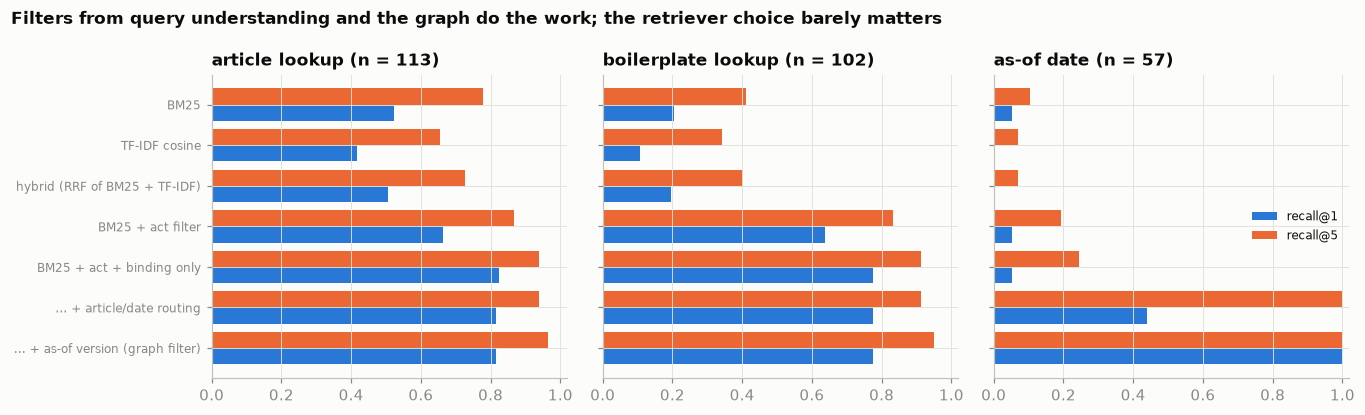

recall@1                                     recall@5                                          MRR  \
family                           article lookup as-of date boilerplate lookup article lookup as-of date boilerplate lookup article lookup   
retriever                                                                                                                                   
BM25                                       0.52       0.05               0.21           0.78       0.11               0.41           0.62   
TF-IDF cosine                              0.42       0.00               0.11           0.65       0.07               0.34           0.50   
hybrid (RRF of BM25 + TF-IDF)              0.50       0.00               0.20           0.73       0.07               0.40           0.58   
BM25 + act filter                          0.66       0.05               0.64           0.87       0.19               0.83           0.75   
BM25 + act + binding only                  0.82       0.05               0.77           0.94       0.25               0.91           0.86   
… + article/date routing                   0.81       0.44               0.77           0.94       1.00               0.91           0.86   
… + as-of version (graph filter)           0.81       1.00               0.77           0.96       1.00               0.95           0.87   

                                                               top-1 is a recital                                
family                           as-of date boilerplate lookup     article lookup as-of date boilerplate lookup  
retriever                                                                                                        
BM25                                   0.06               0.28               0.29       0.33               0.32  
TF-IDF cosine                          0.02               0.18               0.40       0.58               0.45  
hybrid (RRF of BM25 + TF-IDF)          0.02               0.27               0.29       0.35               0.32  
BM25 + act filter                      0.09               0.71               0.25       0.09               0.23  
BM25 + act + binding only              0.10               0.82               0.00       0.00               0.00  
… + article/date routing               0.72               0.82               0.00       0.00               0.00  
… + as-of version (graph filter)       1.00               0.84               0.00       0.00               0.00

In [12]:
STOP = set("the of a an and or to in on for by with which what does do is are from when as article act regulation directive this that it be its deals apply has have been since".split())
tok = lambda s: [w for w in re.findall(r"[a-z0-9]+(?:[-/][a-z0-9]+)*", s.lower()) if w not in STOP]
t0 = time.time()
bm25_hd = BM25Okapi([tok(h + " " + t) for h, t in zip(prov.heading, prov.text)])     # the production default: heading + body
bm25_body = BM25Okapi([tok(t) for t in prov.text])                                    # body only (Trap 3)
tfidf = TfidfVectorizer(tokenizer=tok, lowercase=False, sublinear_tf=True, token_pattern=None).fit(prov.heading + " " + prov.text)
M = tfidf.transform(prov.heading + " " + prov.text)
pid, P_celex, P_type, P_num, P_ver = [prov[c].to_numpy(dtype=object) for c in ["provision_id", "celex", "provision_type", "provision_number", "text_version"]]
P_bind = prov.binding.to_numpy(bool)
P_app = prov.heading.str.lower().str.contains("entry into force").to_numpy(bool)       # the act's own "application" article
WC = prov.word_count.to_numpy()

@lru_cache(maxsize=None)
def s_hd(q): return bm25_hd.get_scores(tok(q))
@lru_cache(maxsize=None)
def s_body(q): return bm25_body.get_scores(tok(q))
@lru_cache(maxsize=None)
def s_tfidf(q): return (M @ tfidf.transform([q]).T).toarray().ravel()
rank = lambda s: np.argsort(-s, kind="stable")

def rrf(*rankings, k=60):
    s = {}
    for ranking in rankings:
        for r_, i in enumerate(ranking[:100], start=1):
            s[i] = s.get(i, 0) + 1 / (k + r_)
    return np.array(sorted(s, key=s.get, reverse=True))

def understand(q):
    '''Query understanding: the act, an article reference, an as-of date, and whether the question asks "from when".'''
    ql = q.lower()
    celex = next((c for a, c in ALIASES if re.search(rf"(?<![\w/]){re.escape(a)}(?![\w/])", ql)), None)
    art = re.search(r"\barticle (\d+[a-z]?)\b", ql)
    m = re.search(r"as of (\d{1,2} \w+ \d{4})", q, re.I)
    return {"celex": celex, "article": art.group(1) if art else None, "as_of": pd.Timestamp(m.group(1)) if m else None,
            "date_intent": bool(re.search(r"from when|apply|applies|applicable", ql))}

_mask = {}
def in_force_mask(d):
    if d not in _mask:
        _mask[d] = np.array([(ver_valid[(c, v)][0] <= d) and (pd.isna(ver_valid[(c, v)][1]) or ver_valid[(c, v)][1] > d) for c, v in zip(P_celex, P_ver)])
    return _mask[d]

def retrieve(q, act=True, binding=True, routing=True, as_of=True, index="hd"):
    '''BM25 plus filters expressed as boosts (as in task 04). as_of=True is the graph filter: only the text version in force on the as-of date.'''
    u = understand(q)
    s = (s_hd(q) if index == "hd" else s_body(q)).astype(float)
    if act and u["celex"]:
        s = np.where(P_celex == u["celex"], s + 1000, s)
    if binding:
        s = np.where(P_bind, s, s - 2000)
    if as_of:
        s = np.where(in_force_mask(u["as_of"] or SNAPSHOT), s, s - 3000)
    if routing and u["celex"] and u["date_intent"]:
        s = np.where((P_celex == u["celex"]) & P_app, s + 500, s)
    elif routing and u["celex"] and u["article"]:
        s = np.where((P_celex == u["celex"]) & (P_num == u["article"]) & (P_type == "article"), s + 500, s)
    return rank(s)

RETRIEVERS = {
    "BM25": lambda q: rank(s_hd(q)),
    "TF-IDF cosine": lambda q: rank(s_tfidf(q)),
    "hybrid (RRF of BM25 + TF-IDF)": lambda q: rrf(rank(s_hd(q)), rank(s_tfidf(q))),
    "BM25 + act filter": lambda q: retrieve(q, binding=False, routing=False, as_of=False),
    "BM25 + act + binding only": lambda q: retrieve(q, routing=False, as_of=False),
    "… + article/date routing": lambda q: retrieve(q, as_of=False),
    "… + as-of version (graph filter)": lambda q: retrieve(q),
}

def score(fn, questions, k=K):
    rows = []
    for g in questions.itertuples():
        r = fn(g.question)
        hits = [pid[i] in g.relevant for i in r[:k]]
        rows.append({"family": g.family, "recall@1": hits[0], f"recall@{k}": any(hits), "MRR": next((1 / (j + 1) for j, h in enumerate(hits) if h), 0.0),
                     "top-1 is a recital": P_type[r[0]] == "recital",
                     f"distinct articles in top-{k}": len({(P_celex[i], P_type[i], P_num[i]) for i in r[:k]})})
    return pd.DataFrame(rows).groupby("family").mean()

t0 = time.time()
board = pd.concat({name: score(fn, gold) for name, fn in RETRIEVERS.items()}, names=["retriever", "family"])
print(f"indexes built and {len(RETRIEVERS)} retrievers × {len(gold)} questions scored in {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), sharey=True)
for ax, fam in zip(axes, ["article lookup", "boilerplate lookup", "as-of date"]):
    sub = board.xs(fam, level="family")
    y = np.arange(len(sub))
    ax.barh(y + 0.2, sub["recall@1"], height=0.4, color=SERIES[0], label="recall@1")
    ax.barh(y - 0.2, sub[f"recall@{K}"], height=0.4, color=SERIES[1], label=f"recall@{K}")
    ax.set_yticks(y); ax.set_yticklabels(sub.index, fontsize=8); ax.invert_yaxis(); ax.set_xlim(0, 1.02)
    ax.set_title(f"{fam} (n = {(gold.family == fam).sum()})")
axes[2].legend(fontsize=8, loc="center right")
fig.suptitle("Filters from query understanding and the graph do the work; the retriever choice barely matters", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()
board[["recall@1", f"recall@{K}", "MRR", "top-1 is a recital"]].unstack("family").round(2)

Plain BM25 ranks the right article first for 52 % of lookups and 21 % of boilerplate lookups, with a recital first 29 % of the time; TF-IDF and fusion do no better. Filters do the work: the act name lifts boilerplate lookups to 0.64, dropping recitals lifts article lookups to 0.82, routing finds Article 113 for every date question. Without the as-of filter the right *version* is first only 44 % of the time.

### A small classifier that earns its place, or not

Documents arriving without structure (a guidance PDF, a pasted extract) need `provision_type` predicted: TF-IDF and logistic regression, trained on acts published before 2023, tested on the five since.

In [13]:
pub = acts.set_index("celex").oj_publication_date
dfc = prov[["celex", "text", "binding"]].assign(published=lambda d: d.celex.map(pub)).drop_duplicates("text")
MODALS = r"\b(?:shall|should|may|must|will|would|could|might|can|cannot)\b"

def fit_binding_classifier(tr, te, mask_modals=False):
    prep = (lambda s: s.str.replace(MODALS, " ", regex=True, case=False)) if mask_modals else (lambda s: s)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50000)
    clf = LogisticRegression(C=4.0, class_weight="balanced", max_iter=2000).fit(vec.fit_transform(prep(tr.text)), tr.binding)
    p = clf.predict(vec.transform(prep(te.text)))
    cm = confusion_matrix(te.binding, p, labels=[False, True])
    return {"test rows": len(te), "macro-F1": f1_score(te.binding, p, average="macro"),
            "recitals called binding": int(cm[0, 1]), "binding called recital": int(cm[1, 0])}

fwd_tr, fwd_te = dfc[dfc.published < CLASSIFIER_SPLIT], dfc[dfc.published >= CLASSIFIER_SPLIT]
r_tr, r_te = train_test_split(prov[["text", "binding"]], test_size=0.3, random_state=SEED, stratify=prov.binding)
shall_rule = fwd_te.text.str.contains(r"\bshall\b")
cm_rule = confusion_matrix(fwd_te.binding, shall_rule, labels=[False, True])
clf_board = pd.DataFrame({
    "random 70/30 split of all rows ⚠": fit_binding_classifier(r_tr, r_te),
    f"forward: acts before {CLASSIFIER_SPLIT.year} → acts from {CLASSIFIER_SPLIT.year}": fit_binding_classifier(fwd_tr, fwd_te),
    "forward, modal verbs masked": fit_binding_classifier(fwd_tr, fwd_te, mask_modals=True),
    "one rule: the text contains 'shall'": {"test rows": len(fwd_te), "macro-F1": f1_score(fwd_te.binding, shall_rule, average="macro"),
                                            "recitals called binding": int(cm_rule[0, 1]), "binding called recital": int(cm_rule[1, 0])},
}).T
print(f"train acts: {sorted(fwd_tr.celex.map(short).unique())}\ntest acts:  {sorted(fwd_te.celex.map(short).unique())}")
print(f"random split: {r_te.text.isin(set(r_tr.text)).mean():.0%} of test rows have an identical twin in training")
clf_board.astype({"test rows": int, "recitals called binding": int, "binding called recital": int}).round({"macro-F1": 3})

train acts: ['Cybersecurity Act', 'Data Governance Act', 'Digital Markets Act', 'Digital Services Act', 'GDPR', 'NIS2 Directive', 'ePrivacy Directive']
test acts:  ['AI Act', 'Cyber Resilience Act', 'Data Act', 'Digital Omnibus on AI', 'Product Liability Directive (2024)']
random split: 21% of test rows have an identical twin in training


,test rows,macro-F1,recitals called binding,binding called recital
random 70/30 split of all rows ⚠,756,0.983,1,12
forward: acts before 2023 → acts from 2023,912,0.966,7,23
"forward, modal verbs masked",912,0.896,30,60
one rule: the text contains 'shall',912,0.959,2,34


The random split flatters (0.983): 21 % of its test rows have an identical twin in training. The forward number, 0.966, barely beats "contains *shall*" (0.959), which calls only 2 recitals binding against the classifier's 7; masking modal verbs drops it to 0.896. Drafting convention carries the label, so the rule ships and the classifier stays a reference.

## 5 · As of a date: plain retrieval against graph-filtered retrieval, and the operating point

*Part B · Given model · package `answer_system` and `verify_claim`; C3 asks you to own the context budget.*

Four ways to answer the 57 as-of questions, each with a perfect reader so only the choice of text differs: the current text; all versions without an as-of filter; the graph (version in force plus curated rules); and, for "does it apply yet?", no dates at all.

without an as-of filter the retriever ranked the amended (consolidated) Article 113 first for 100% of the 57 date questions, whatever the as-of date


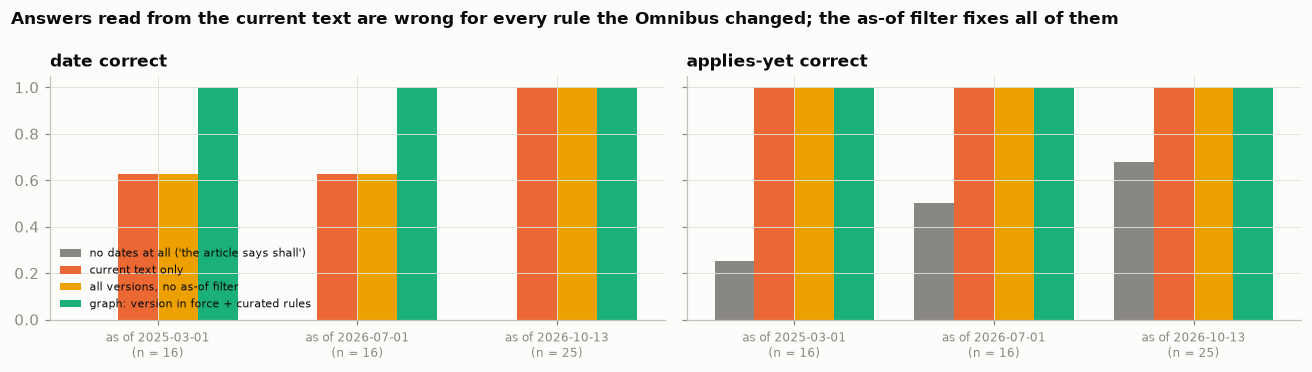

date correct                       applies-yet correct                       citation in force  \
as_of                                        2025-03-01 2026-07-01 2026-10-13          2025-03-01 2026-07-01 2026-10-13        2025-03-01   
method                                                                                                                                      
no dates at all ('the article says shall')         0.00       0.00        0.0                0.25        0.5       0.68               0.0   
current text only                                  0.62       0.62        1.0                1.00        1.0       1.00               0.0   
all versions, no as-of filter                      0.62       0.62        1.0                1.00        1.0       1.00               0.0   
graph: version in force + curated rules            1.00       1.00        1.0                1.00        1.0       1.00               1.0   

                                                                  
as_of                                      2026-07-01 2026-10-13  
method                                                            
no dates at all ('the article says shall')        0.0        1.0  
current text only                                 0.0        1.0  
all versions, no as-of filter                     0.0        1.0  
graph: version in force + curated rules           1.0        1.0

In [14]:
ai_art = {(r.text_version, r.provision_number): r for r in prov[(prov.celex == AI_ACT) & (prov.provision_type == "article")].itertuples()}
def date_for(num, tier, version):
    r = ai_art.get((version, num))
    return None if (r is None or version is None) else applies_from(r, tier, version)[0]

no_asof = RETRIEVERS["… + article/date routing"]
rows = []
for g in gold[gold.family == "as-of date"].itertuples():
    r = no_asof(g.question)
    v_plain = next((P_ver[i] for i in r[:10] if P_celex[i] == AI_ACT and P_app[i]), None)   # the version of the first Art. 113 the retriever returns
    for method, v in [("current text only", "consolidated"), ("all versions, no as-of filter", v_plain), ("graph: version in force + curated rules", g.version)]:
        d = date_for(g.num, g.tier, v)
        rows.append({"as_of": g.as_of.date(), "method": method, "date correct": d == g.answer_date,
                     "applies-yet correct": d is not None and ((d <= g.as_of) == (g.answer_date <= g.as_of)), "citation in force": v == g.version})
    rows.append({"as_of": g.as_of.date(), "method": "no dates at all ('the article says shall')", "date correct": False,
                 "applies-yet correct": g.answer_date <= g.as_of, "citation in force": g.version == "consolidated"})
asof_res = pd.DataFrame(rows)
picked = [next((P_ver[i] for i in no_asof(q)[:10] if P_celex[i] == AI_ACT and P_app[i]), None) for q in gold[gold.family == "as-of date"].question]
print(f"without an as-of filter the retriever ranked the amended (consolidated) Article 113 first for {np.mean([p == 'consolidated' for p in picked]):.0%} "
      f"of the {len(picked)} date questions, whatever the as-of date")
asof_tbl = asof_res.groupby(["method", "as_of"]).mean().unstack("as_of")
order = ["no dates at all ('the article says shall')", "current text only", "all versions, no as-of filter", "graph: version in force + curated rules"]
asof_tbl = asof_tbl.loc[order]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, metric in zip(axes, ["date correct", "applies-yet correct"]):
    sub = asof_tbl[metric]
    x = np.arange(len(sub.columns)); w = 0.2
    for j, (m_, color) in enumerate(zip(order, [MUTED, SERIES[1], SERIES[3], SERIES[2]])):
        ax.bar(x + (j - 1.5) * w, sub.loc[m_], width=w, color=color, label=m_)
    ax.set_xticks(x); ax.set_xticklabels([f"as of {c}\n(n = {(gold.as_of.dt.date == c).sum()})" for c in sub.columns], fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_title(metric)
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Answers read from the current text are wrong for every rule the Omnibus changed; the as-of filter fixes all of them", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()
asof_tbl.round(2)

The graph's 1.00 is true by construction: the golden answers come from the same rules and version table, so the graph row is the reference and the other rows measure what each shortcut loses. It cannot show the rules are right; only an independent, counsel-labelled sample can (tasks C1, C4). The losses: on the snapshot date every dated method is right, since today's text *is* the current text; on the earlier dates, current-text answers get 38 % of dates wrong (the Chapter III high-risk articles and Articles 102–110) and cite a text not yet law. Retrieval over all versions does no better: it picks the amended Article 113 every time. With no dates, "does it apply yet?" is right for half.

### Amendments: what each source of evidence knows

In [15]:
hy = RETRIEVERS["hybrid (RRF of BM25 + TF-IDF)"]
amd_q["plain retrieval (amending act in top-5)"] = [any(P_celex[i] == OMNIBUS for i in hy(q)[:K]) for q in amd_q.question]
amd_q["diff of the two text versions"] = amd_q.target.isin(diff_changed)
amd_q["as-published text only"] = False
work_iri = lambda t: IRI("work", AI_ACT, "article" if t.startswith("Article") else "annex", t.split()[1])
amd_q["graph: amendment edges"] = [KG.query(PFX + f"ASK {{ ?a a reg:Amendment ; reg:target {work_iri(t)} }}").askAnswer for t in amd_q.target]
amd_tbl = pd.DataFrame({m: {"accuracy": accuracy_score(amd_q.label, amd_q[m]), "precision (amended)": precision_score(amd_q.label, amd_q[m], zero_division=0),
                            "recall (amended)": recall_score(amd_q.label, amd_q[m])}
                        for m in ["as-published text only", "plain retrieval (amending act in top-5)", "diff of the two text versions", "graph: amendment edges"]}).T
amd_tbl.round(3)

,accuracy,precision (amended),recall (amended)
as-published text only,0.662,0.000,0.000
plain retrieval (amending act in top-5),0.699,0.540,0.756
diff of the two text versions,0.812,0.643,1.000
graph: amendment edges,1.000,1.000,1.000


The published text alone never says "amended". Saying "yes" when an Omnibus passage reaches the top five scores 70 % with 54 % precision: Omnibus recitals mention articles they do not amend. The diff finds every amendment plus 25 false ones. The graph is again right by construction (labels and edges come from the same parse), which is the point: an amendment edge is extracted once and validated, not inferred at question time.

### The board question, answered as structured data

The answer is a query: the role's obligations in the parts of the Act its tier brings in (`TIER_SCOPE`, owned by counsel), dated under the text in force.

In [16]:
TIER_SCOPE = {   # which parts of the AI Act a system's classification brings into play (Art. 6, 50, 51-55) — a teaching reading, not legal advice
    "annex_iii": lambda c, s: (c == "III" and s in {"1", "2", "3", "5"}) or (c == "IX" and s in {"1", "2"}),
    "annex_i":   lambda c, s: (c == "III" and s in {"1", "2", "3", "5"}) or (c == "IX" and s in {"1", "2"}),
    "transparency": lambda c, s: c == "IV",
    "gpai":      lambda c, s: c == "V" and s in {"2", "3"},
}
OBLIGATIONS_Q = """SELECT ?article ?heading ?chapter ?section ?tier ?applies_from ?rule ?clauses WHERE {
  ?o a reg:Obligation ; reg:bearer $actor ; reg:statedIn ?p ; reg:statements ?clauses .
  ?p reg:partOf $act ; reg:provisionType "article" ; reg:number ?article ; reg:heading ?heading . """ + IN_FORCE + """
  OPTIONAL { ?p reg:chapter ?chapter } OPTIONAL { ?p reg:section ?section }
  ?ap reg:of ?p ; reg:tier ?tier ; reg:appliesFrom ?applies_from ; reg:rule ?rule . FILTER NOT EXISTS { ?ap reg:paragraphs ?x } }"""

def answer_system(system, as_of):
    '''The structured answer the copilot must give: {obligations[], articles[], applies_from}, every field read from the KG.'''
    df = sparql(OBLIGATIONS_Q, actor=IRI("actor", system["role"]), act=IRI("act", AI_ACT), asof=as_of.date())
    tier = system["tier"]
    keep = df.apply(lambda r: (r.article == "4" or TIER_SCOPE[tier](r.chapter or "", r.section or "")) and r.tier in ("any", tier), axis=1) if len(df) else []
    df = df[keep].sort_values(["applies_from", "article"], key=lambda s: s.map(n_int) if s.name == "article" else s)
    obligations = [{"article": f"Article {r.article}", "heading": r.heading, "applies_from": str(r.applies_from), "applies_now": r.applies_from <= as_of.date(),
                    "rule": r.rule} for r in df.itertuples()]
    return {"system": system["name"], "role": system["role"], "as_of": str(as_of.date()), "text_version": version_in_force(AI_ACT, as_of),
            "obligations": obligations, "articles": [o["article"] for o in obligations],
            "applies_from": min((o["applies_from"] for o in obligations), default=None), "fully_applicable_from": max((o["applies_from"] for o in obligations), default=None)}

SYSTEMS = [
    {"name": "CV-screening tool bought in and run by HR (Annex III, employment)", "role": "deployer", "tier": "annex_iii"},
    {"name": "The same CV-screening tool, built in-house and placed on the market", "role": "provider", "tier": "annex_iii"},
    {"name": "Safety component of a machine (Annex I product legislation)", "role": "provider", "tier": "annex_i"},
    {"name": "Customer-service chatbot we build", "role": "provider", "tier": "transparency"},
    {"name": "General-purpose model released to downstream developers", "role": "gpai_provider", "tier": "gpai"},
]
summary = []
for s in SYSTEMS:
    for d in [pd.Timestamp("2026-07-01"), SNAPSHOT]:
        a = answer_system(s, d)
        summary.append({"system": s["name"], "as of": a["as_of"], "text": a["text_version"], "articles": len(a["articles"]),
                        "apply now": sum(o["applies_now"] for o in a["obligations"]), "earliest": a["applies_from"], "fully applicable": a["fully_applicable_from"]})
display(pd.DataFrame(summary).set_index(["system", "as of"]))
a = answer_system(SYSTEMS[0], SNAPSHOT)
print(json.dumps({**a, "obligations": a["obligations"][:3] + [f"… {len(a['obligations']) - 3} more"]}, indent=1, ensure_ascii=False)[:1400])

text  articles  apply now    earliest  \
system                                                              as of                                                       
CV-screening tool bought in and run by HR (Annex III, employment)   2026-07-01  as_published         4          1  2025-02-02   
                                                                    2026-10-13  consolidated         4          1  2025-02-02   
The same CV-screening tool, built in-house and placed on the market 2026-07-01  as_published        15          1  2025-02-02   
                                                                    2026-10-13  consolidated        15          5  2025-02-02   
Safety component of a machine (Annex I product legislation)         2026-07-01  as_published        15          1  2025-02-02   
                                                                    2026-10-13  consolidated        15          5  2025-02-02   
Customer-service chatbot we build                                   2026-07-01  as_published         2          1  2025-02-02   
                                                                    2026-10-13  consolidated         2          2  2025-02-02   
General-purpose model released to downstream developers             2026-07-01  as_published         2          2  2025-08-02   
                                                                    2026-10-13  consolidated         2          2  2025-08-02   

                                                                               fully applicable  
system                                                              as of                        
CV-screening tool bought in and run by HR (Annex III, employment)   2026-07-01       2026-08-02  
                                                                    2026-10-13       2027-12-02  
The same CV-screening tool, built in-house and placed on the market 2026-07-01       2026-08-02  
                                                                    2026-10-13       2027-12-02  
Safety component of a machine (Annex I product legislation)         2026-07-01       2027-08-02  
                                                                    2026-10-13       2028-08-02  
Customer-service chatbot we build                                   2026-07-01       2026-08-02  
                                                                    2026-10-13       2026-08-02  
General-purpose model released to downstream developers             2026-07-01       2025-08-02  
                                                                    2026-10-13       2025-08-02

{
 "system": "CV-screening tool bought in and run by HR (Annex III, employment)",
 "role": "deployer",
 "as_of": "2026-10-13",
 "text_version": "consolidated",
 "obligations": [
  {
   "article": "Article 4",
   "heading": "AI literacy",
   "applies_from": "2025-02-02",
   "applies_now": true,
   "rule": "32024R1689|4"
  },
  {
   "article": "Article 25",
   "heading": "Responsibilities along the AI value chain",
   "applies_from": "2027-12-02",
   "applies_now": false,
   "rule": "32024R1689|12"
  },
  {
   "article": "Article 26",
   "heading": "Obligations of deployers of high-risk AI systems",
   "applies_from": "2027-12-02",
   "applies_now": false,
   "rule": "32024R1689|12"
  },
  "… 1 more"
 ],
 "articles": [
  "Article 4",
  "Article 25",
  "Article 26",
  "Article 27"
 ],
 "applies_from": "2025-02-02",
 "fully_applicable_from": "2027-12-02"
}


The CV-screening tool has four deployer obligations on both dates; the high-risk ones were due from 2 August 2026 under the July text and from 2 December 2027 under the October one. Built in-house it carries 15 provider obligations, 5 already applicable: our selectors, read literally, make Chapter III Section 5 and Chapter IX apply from 2 August 2026, before the requirements they assess; counsel must confirm. A result that surprising is for the copilot to escalate, not state.

Every claim a generator makes is then checked against the graph, field by field:

In [17]:
def verify_claim(c):
    '''Check one generated claim against the KG: the cited provision exists in the text in force, binds, names the actor, and carries the claimed date.'''
    kind = c.get("type", "article")
    rows_ = sparql("""SELECT ?p ?t WHERE { ?p reg:partOf $act ; reg:provisionType ?t ; reg:number "$num" . FILTER(?t = "$kind") """ + IN_FORCE + " }",
                   act=IRI("act", AI_ACT), num=c["number"], kind=kind, asof=c["as_of"])
    checks = {"in force on the as-of date": len(rows_) > 0}
    if checks["in force on the as-of date"]:
        checks["binding (not a recital)"] = rows_.t.iloc[0] in ("article", "annex")
    if checks.get("binding (not a recital)"):
        p = f"<{rows_.p.iloc[0]}>"
        checks["actor bears an obligation there"] = bool(KG.query(PFX + f"ASK {{ ?o reg:statedIn {p} ; reg:bearer {IRI('actor', c['actor'])} }}").askAnswer)
        dd = sparql(f"SELECT ?d WHERE {{ ?ap reg:of {p} ; reg:tier ?t ; reg:appliesFrom ?d . FILTER(?t IN (\"any\", \"{c['tier']}\")) FILTER NOT EXISTS {{ ?ap reg:paragraphs ?x }} }}")
        checks["date matches the KG"] = str(dd.d.iloc[0]) == c["applies_from"] if len(dd) else False
    return {"claim": c["text"], "verdict": "supported" if all(checks.values()) and len(checks) == 4 else "REJECT",
            "failed": ", ".join(k for k, v in checks.items() if not v) or "—"}

CLAIMS = [
    {"text": "Deployers of Annex III systems must meet Article 26 from 2 Dec 2027", "number": "26", "actor": "deployer", "tier": "annex_iii", "applies_from": "2027-12-02", "as_of": "2026-10-13"},
    {"text": "Deployers of Annex III systems must meet Article 26 from 2 Aug 2026", "number": "26", "actor": "deployer", "tier": "annex_iii", "applies_from": "2026-08-02", "as_of": "2026-10-13"},
    {"text": "(same claim, asked on 1 July 2026)", "number": "26", "actor": "deployer", "tier": "annex_iii", "applies_from": "2026-08-02", "as_of": "2026-07-01"},
    {"text": "Recital 91 obliges deployers to monitor the system", "number": "91", "type": "recital", "actor": "deployer", "tier": "annex_iii", "applies_from": "2026-08-02", "as_of": "2026-07-01"},
    {"text": "Article 4a lets providers process special-category data for bias detection", "number": "4a", "actor": "provider", "tier": "any", "applies_from": "2026-07-27", "as_of": "2026-07-01"},
    {"text": "Article 16 sets obligations for deployers", "number": "16", "actor": "deployer", "tier": "annex_iii", "applies_from": "2027-12-02", "as_of": "2026-10-13"},
]
pd.DataFrame([verify_claim(c) for c in CLAIMS])

,claim,verdict,failed
0,Deployers of Annex III systems must meet Article 26 from 2 Dec 2027,supported,—
1,Deployers of Annex III systems must meet Article 26 from 2 Aug 2026,REJECT,date matches the KG
2,"(same claim, asked on 1 July 2026)",supported,—
3,Recital 91 obliges deployers to monitor the system,REJECT,binding (not a recital)
4,Article 4a lets providers process special-category data for bias d...,REJECT,in force on the as-of date
5,Article 16 sets obligations for deployers,REJECT,actor bears an obligation there


A superseded date, a recital, an article not yet in force and the wrong actor are each rejected with a reason; the July claim passes. This verifier is the safety net for task S1.

### The operating point: how much context per answer

A generator receives *k* passages, and Article 1 of the Omnibus alone is about 26,000 tokens. The operating point is *k* under a context budget (latency, cost, facts lost in long contexts).

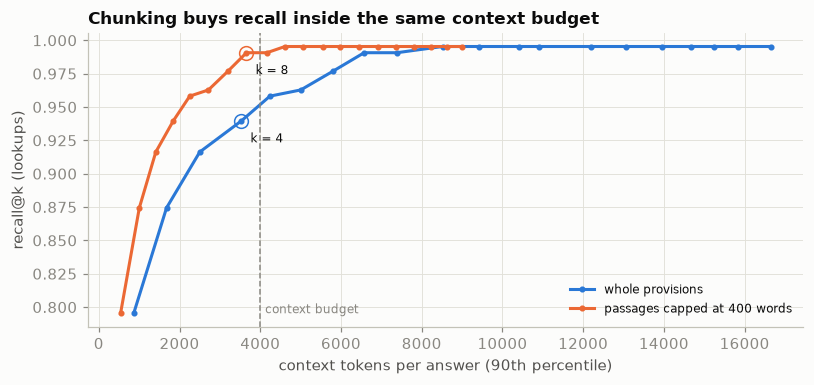

budget 4,000 tokens → whole provisions: k = 4, recall 0.940 · capped passages: k = 8, recall 0.991
cost at k = 8: €0.0128 per answer · €26 per month for 2,000 questions (assumed prices) · longest provision: Digital Omnibus on AI Art. 1, 19,276 words ≈ 26,023 tokens


In [18]:
best = RETRIEVERS["… + as-of version (graph filter)"]
lk = gold[gold.family.isin(["article lookup", "boilerplate lookup"])]
ranked = [best(q)[:20] for q in lk.question]
op = []
for k in range(1, 21):
    rec = np.mean([any(pid[i] in rel for i in r[:k]) for r, rel in zip(ranked, lk.relevant)])
    full = np.array([WC[r[:k]].sum() for r in ranked]) * TOKENS_PER_WORD
    cap = np.array([np.minimum(WC[r[:k]], PASSAGE_CAP_WORDS).sum() for r in ranked]) * TOKENS_PER_WORD
    op.append({"k": k, "recall@k": rec, "p90 tokens · whole provisions": np.percentile(full, 90), "p90 tokens · capped passages": np.percentile(cap, 90),
               "mean tokens · capped passages": cap.mean()})
op = pd.DataFrame(op).set_index("k")
k_full = int(op[op["p90 tokens · whole provisions"] <= CONTEXT_BUDGET_TOKENS].index.max())
k_cap = int(op[op["p90 tokens · capped passages"] <= CONTEXT_BUDGET_TOKENS].index.max())
eur = lambda tok_in: (tok_in + PROMPT_OVERHEAD_TOKENS) / 1e6 * EUR_PER_M_INPUT + ANSWER_TOKENS / 1e6 * EUR_PER_M_OUTPUT
cost = eur(op.loc[k_cap, "mean tokens · capped passages"])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(op["p90 tokens · whole provisions"], op["recall@k"], "-o", ms=3, lw=2, color=SERIES[0], label="whole provisions")
ax.plot(op["p90 tokens · capped passages"], op["recall@k"], "-o", ms=3, lw=2, color=SERIES[1], label=f"passages capped at {PASSAGE_CAP_WORDS} words")
ax.axvline(CONTEXT_BUDGET_TOKENS, color=MUTED, ls="--", lw=1); ax.text(CONTEXT_BUDGET_TOKENS * 1.03, op["recall@k"].min(), "context budget", color=MUTED, fontsize=8)
for kk, col, color in [(k_full, "p90 tokens · whole provisions", SERIES[0]), (k_cap, "p90 tokens · capped passages", SERIES[1])]:
    ax.plot([op.loc[kk, col]], [op.loc[kk, "recall@k"]], "o", ms=9, mfc="none", color=color)
    ax.annotate(f"k = {kk}", (op.loc[kk, col], op.loc[kk, "recall@k"]), xytext=(6, -14), textcoords="offset points", fontsize=8)
ax.set_xlabel("context tokens per answer (90th percentile)"); ax.set_ylabel("recall@k (lookups)")
ax.set_title("Chunking buys recall inside the same context budget"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print(f"budget {CONTEXT_BUDGET_TOKENS:,} tokens → whole provisions: k = {k_full}, recall {op.loc[k_full, 'recall@k']:.3f} · "
      f"capped passages: k = {k_cap}, recall {op.loc[k_cap, 'recall@k']:.3f}")
print(f"cost at k = {k_cap}: €{cost:.4f} per answer · €{cost * QUESTIONS_PER_MONTH:,.0f} per month for {QUESTIONS_PER_MONTH:,} questions (assumed prices) · "
      f"longest provision: {prov.loc[prov.word_count.idxmax(), 'act']} Art. {prov.loc[prov.word_count.idxmax(), 'provision_number']}, "
      f"{WC.max():,} words ≈ {WC.max() * TOKENS_PER_WORD:,.0f} tokens")

Within the assumed 4,000-token budget, whole provisions allow *k* = 4 at the 90th percentile (recall 0.940); passages capped at 400 words allow *k* = 8 (recall 0.991). At the assumed prices an answer costs about €0.013, 2,000 a month about €26: the budget and the reviewer's attention bind, not cost (task C3).

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

**Trap 1 — recitals treated as binding.** Plain BM25 ranks a recital first for 29 % of article lookups, and the naive extractor reads 123 obligations out of recitals. Fix: binding provisions only, SHACL shape in CI.

**Trap 2 — ignoring dates of application.** Answers from the current text get 38 % of dates wrong for questions asked before the Omnibus applied; with no dates, "does it apply yet?" is right for 51 %. The Cellar metadata is no rescue: it lists the superseded 2 Aug 2027 and lacks 27 Jul 2026, 2 Dec 2026 and 2 Dec 2027. Fix: every answer carries an as-of date; dates come from the curated rules via the graph.

**Trap 3 — the golden set leaks its generating field.** Lookup questions come from headings, which the index contains: the full pipeline's recall@1 is 0.80 with headings indexed, 0.49 on the body alone. Fix: report both; add hand-written questions (C1).

**Trap 4 — duplicate provisions across versions and acts.** Without version filtering, BM25's top five holds 4.0 distinct articles; shared headings hold plain recall@1 at 0.21 until the act filter lifts it to 0.64. Fix: collapse versions; detect the act.

In [19]:
lookups = gold[gold.family.isin(["article lookup", "boilerplate lookup"])]
b = lambda name, fam, col: board.loc[(name, fam), col]
leak = {"BM25, heading + text": score(lambda q: retrieve(q, as_of=True), lookups.assign(family="lookups")),
        "BM25, text only": score(lambda q: retrieve(q, as_of=True, index="body"), lookups.assign(family="lookups"))}
cellar_dates = set(dates[(dates.celex == AI_ACT) & (dates.source == "cellar_metadata")].date)
needed = set(cur.date)
pre = asof_res[asof_res.as_of < pd.Timestamp("2026-07-27").date()].groupby("method").mean(numeric_only=True)
traps = pd.DataFrame([
    {"trap": "1 · recitals treated as binding", "measure": "top-1 hit is a recital (article lookups)",
     "naive": b("BM25", "article lookup", "top-1 is a recital"), "honest": b("BM25 + act + binding only", "article lookup", "top-1 is a recital")},
    {"trap": "1 · recitals treated as binding", "measure": "obligations the naive extractor reads from recitals",
     "naive": val.loc["naive extraction (any modal, every provision)", "obligations in recitals"], "honest": val.loc["strict extraction (shall, binding provisions)"].get("obligations in recitals", 0)},
    {"trap": "2 · ignoring application dates", "measure": "date correct, as-of dates before the Omnibus",
     "naive": pre.loc["current text only", "date correct"], "honest": pre.loc["graph: version in force + curated rules", "date correct"]},
    {"trap": "2 · ignoring application dates", "measure": "'applies yet?' correct, all as-of questions",
     "naive": asof_res[asof_res.method.str.startswith("no dates")]["applies-yet correct"].mean(),
     "honest": asof_res[asof_res.method.str.startswith("graph")]["applies-yet correct"].mean()},
    {"trap": "2 · ignoring application dates", "measure": "curated dates missing from the cellar metadata",
     "naive": len(needed - cellar_dates), "honest": 0},
    {"trap": "3 · golden set leaks its generating field", "measure": "recall@1, lookups (full pipeline)",
     "naive": leak["BM25, heading + text"].loc["lookups", "recall@1"], "honest": leak["BM25, text only"].loc["lookups", "recall@1"]},
    {"trap": "4 · duplicate provisions", "measure": f"distinct articles in top-{K} (article lookups)",
     "naive": b("BM25", "article lookup", f"distinct articles in top-{K}"), "honest": b("… + as-of version (graph filter)", "article lookup", f"distinct articles in top-{K}")},
    {"trap": "4 · duplicate provisions", "measure": "recall@1, boilerplate headings (no act filter → act filter)",
     "naive": b("BM25", "boilerplate lookup", "recall@1"), "honest": b("BM25 + act filter", "boilerplate lookup", "recall@1")},
]).set_index(["trap", "measure"])
print(f"cellar metadata lists {sorted(d.date().isoformat() for d in cellar_dates & {pd.Timestamp('2027-08-02')})} (superseded) and lacks "
      f"{sorted(d.date().isoformat() for d in needed - cellar_dates)}")
traps.round(2)

cellar metadata lists ['2027-08-02'] (superseded) and lacks ['2026-07-27', '2026-12-02', '2027-12-02']


naive  honest
trap                                      measure                                                                    
1 · recitals treated as binding           top-1 hit is a recital (article lookups)                       0.29    0.00
                                          obligations the naive extractor reads from recitals          123.00    0.00
2 · ignoring application dates            date correct, as-of dates before the Omnibus                   0.62    1.00
                                          'applies yet?' correct, all as-of questions                    0.51    1.00
                                          curated dates missing from the cellar metadata                 3.00    0.00
3 · golden set leaks its generating field recall@1, lookups (full pipeline)                              0.80    0.49
4 · duplicate provisions                  distinct articles in top-5 (article lookups)                   4.02    5.00
                                          recall@1, boilerplate headings (no act filter → act filter)    0.21    0.64

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the law moves, the index does not

*Part C · Productionise · what your monitoring plan must catch (C5): knowledge drift and the re-index trigger.*

In task 02 the model went blind while its inputs stayed still. Here the model never changes; the law does. Score an index built before the Omnibus, never refreshed, against the law in force.

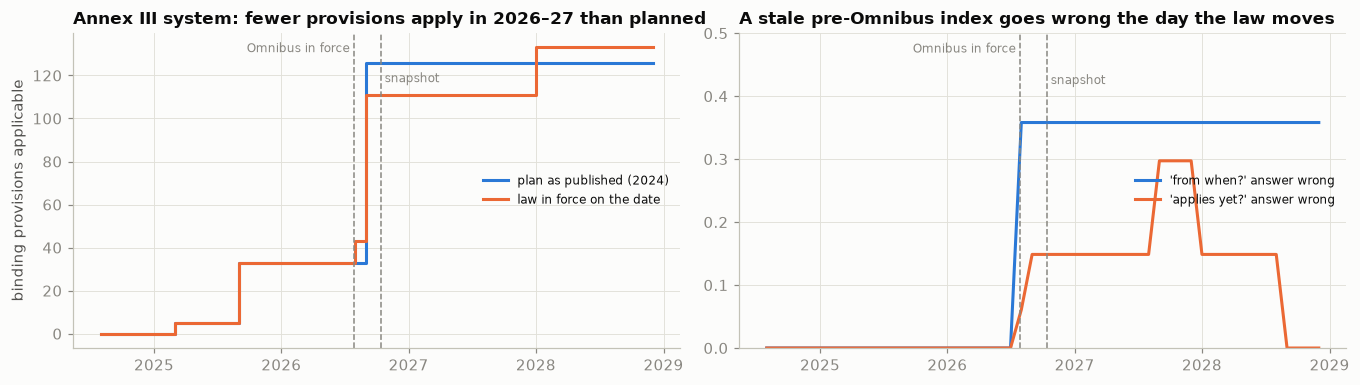

on the snapshot date the 2024 plan has 126 binding provisions applicable to an Annex III system; the law in force has 111, and 133 once everything applies
after the Omnibus: 36% of (provision × tier) dates differ; 'applies yet?' errors peak at 30% (Sep 2027 – Dec 2027, monthly grid) and last until Aug 2028; the stale index lacks 7 provision-tier entries inserted by the Omnibus


In [20]:
months = pd.date_range(TIMELINE_START, TIMELINE_END, freq="MS")
works_t = []
for v in ["as_published", "consolidated"]:
    for r in aib[(aib.text_version == v)].itertuples():
        for t in (["annex_iii", "annex_i"] if (r.chapter == "III" and r.section in S13) else ["any"]):
            works_t.append({"version": v, "key": (r.provision_type, r.provision_number, t), "date": applies_from(r, t, v)[0]})
works_t = pd.DataFrame(works_t)
plan = {v: works_t[works_t.version == v].set_index("key").date for v in ["as_published", "consolidated"]}
iii = lambda s: s[[k[2] in ("any", "annex_iii") for k in s.index]]
curve, drift = [], []
for m_ in months:
    v = version_in_force(AI_ACT, m_)
    truth, stale = plan[v], plan["as_published"]          # a stale index was built before the Omnibus and never refreshed
    curve.append({"month": m_, "plan as published (2024)": int((iii(stale) <= m_).sum()), "law in force on the date": int((iii(truth) <= m_).sum())})
    common = truth.index.intersection(stale.index)
    drift.append({"month": m_, "from-when wrong": float((truth[common] != stale[common]).mean()),
                  "applies-yet wrong": float(((truth[common] <= m_) != (stale[common] <= m_)).mean()),
                  "provisions the stale index lacks": len(truth.index.difference(stale.index))})
curve, drift = pd.DataFrame(curve).set_index("month"), pd.DataFrame(drift).set_index("month")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
ax = axes[0]
ax.step(curve.index, curve["plan as published (2024)"], where="post", lw=2, color=SERIES[0], label="plan as published (2024)")
ax.step(curve.index, curve["law in force on the date"], where="post", lw=2, color=SERIES[1], label="law in force on the date")
ax.set_title("Annex III system: fewer provisions apply in 2026–27 than planned"); ax.set_ylabel("binding provisions applicable")
ax = axes[1]
ax.plot(drift.index, drift["from-when wrong"], lw=2, color=SERIES[0], label="'from when?' answer wrong")
ax.plot(drift.index, drift["applies-yet wrong"], lw=2, color=SERIES[1], label="'applies yet?' answer wrong")
ax.set_ylim(0, max(0.5, drift.max(numeric_only=True)[["from-when wrong", "applies-yet wrong"]].max() * 1.15))
ax.set_title("A stale pre-Omnibus index goes wrong the day the law moves")
for ax in axes:
    for x, l, h, ha in [(ver_valid[(AI_ACT, "consolidated")][0], "Omnibus in force ", 0.97, "right"), (SNAPSHOT, " snapshot", 0.87, "left")]:
        ax.axvline(x, color=MUTED, ls="--", lw=1); ax.text(x, ax.get_ylim()[1] * h, l, color=MUTED, fontsize=8, va="top", ha=ha)
    ax.legend(fontsize=8, loc="center right"); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()
snap = curve.loc[SNAPSHOT.to_period("M").to_timestamp()]
print(f"on the snapshot date the 2024 plan has {snap.iloc[0]} binding provisions applicable to an Annex III system; the law in force has {snap.iloc[1]}, "
      f"and {curve['law in force on the date'].max()} once everything applies")
top = drift.index[drift["applies-yet wrong"] == drift["applies-yet wrong"].max()]
last_wrong = drift.index[drift["applies-yet wrong"] > 0].max()
print(f"after the Omnibus: {drift.loc[SNAPSHOT.to_period('M').to_timestamp(), 'from-when wrong']:.0%} of (provision × tier) dates differ; "
      f"'applies yet?' errors peak at {drift['applies-yet wrong'].max():.0%} ({top.min():%b %Y} – {top.max():%b %Y}, monthly grid) and last until {last_wrong:%b %Y}; the stale index lacks "
      f"{int(drift['provisions the stale index lacks'].max())} provision-tier entries inserted by the Omnibus")

On the snapshot date the law in force makes 15 fewer provisions applicable to an Annex III system than the 2024 plan did (111 against 126). Until 27 July 2026 a stale index is perfect. The day the Omnibus applies, 36 % of its (provision × tier) dates become wrong and it lacks the seven inserted provisions; its "does it apply yet?" errors peak at 30 % from September to December 2027, and persist until August 2028. No input statistic shows it, and the old golden set still passes. The signals that catch it come from the graph:

In [21]:
monitor = cq_results["CQ4 · Which acts were amended after the date of the text the dataset holds for them?"]   # the staleness signal, straight from the graph
print(f"stale texts on the snapshot date: {len(monitor)}"); display(monitor)
print(f"golden as-of answers that change between the two snapshots of the AI Act: "
      f"{(plan['as_published'][plan['as_published'].index.intersection(plan['consolidated'].index)] != plan['consolidated'][plan['as_published'].index.intersection(plan['consolidated'].index)]).mean():.0%} "
      f"of (provision × tier) dates; amended or inserted provisions: {len(parsed)} of {len(works)}")

stale texts on the snapshot date: 1


,act,amending_act,published,in_dataset,text_valid_from
0,Cyber Resilience Act,32025R0327,2025-03-05,False,2024-12-10


golden as-of answers that change between the two snapshots of the AI Act: 36% of (provision × tier) dates; amended or inserted provisions: 45 of 133


- **a new amendment edge** (the Omnibus was published three days before it entered into force);
- **an amendment newer than the consolidated text held**, which fires today for the Cyber Resilience Act;
- **answer churn on re-index**: 36 % of AI Act date answers changed with this one amendment.

Task 02's retraining trigger becomes a re-index trigger: any signal starts ingest, graph rebuild, SHACL and the gate; the old index stays `champion` until the new one passes.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The spine made concrete with this notebook's findings: the minimum your repository must contain.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/reg_copilot/`; `POST /ask {question, as_of}` → `{obligations[], articles[], applies_from, text_version}`; compose with Postgres and Neo4j or an RDF store (22.6 k triples) |
| Monitoring (S04) | Citation validity (cited text in force on the as-of date and binding; current-text answers scored 0.00 before 27 Jul 2026), verifier reject rate, refusal rate, p90 context tokens ≤ 4,000, cost per answer ≈ €0.013 |
| CI/CD gate (S05) | Frozen, fingerprinted golden set (405 questions). Gate: lookup recall@5 ≥ 0.95, SHACL conforms, and agreement with a counsel-labelled sample of dates and amendments. Not the graph's 1.00 on the generated sets, which cannot fail; those sets gate retrieval and generation. Classifier only if it beats the *shall* rule (0.959) |
| MLflow tracking and registry (S06) | Corpus SHA-256, selector-table version, chunking (*k* = 8, 400-word cap), retriever and prompt versions, golden-set scores; index-plus-graph bundle with `champion` / `challenger` aliases |
| Offline / online training and serving | Offline re-index and graph rebuild on refresh or amendment; online Q&A, `as_of` defaulting to today |
| Data and model drift | Knowledge drift: the Omnibus changed 45 of 133 binding AI Act provisions and 36 % of dates; a stale index is wrong on "applies yet?" for up to 30 % of entries. Signals: new amendment edge, amendment newer than the held text (fires now for the CRA), answer churn |
| Knowledge base and context (S07–S09) | Version–provision–obligation–actor–date graph with amendment edges; six SHACL shapes; four competency questions. Ablation against the graph path (1.00 by construction) measures what other methods lose: as-of date accuracy 0.62 before the Omnibus, amendment accuracy 0.70 |
| GenAI and context engineering (S10–S11) | Structured answers verified claim by claim (`verify_claim`); injection tests through passages; risk tier as a rule-based checklist over the graph, since the data has no tier labels (S3) |
| Governance | Not legal advice: counsel owns the selectors and `TIER_SCOPE`; CC BY 4.0 attribution; every answer logs its text version and as-of date; the copilot itself is likely within Art. 50(1) (our reading) |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap, with a test.** No recital citable as an obligation; `as_of` mandatory and stated; golden set also scored on a body-only index, plus 40 hand-written questions that avoid heading words, with recall@5 and MRR on both sets; versions collapsed; tests that every curated date row has a selector found in Article 113; and a check the graph can fail: a counsel-labelled sample of dates and amendment targets it must reproduce.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `CONTEXT_BUDGET_TOKENS`, `PASSAGE_CAP_WORDS`, prices and load; show recall@k, cost and latency; record *k*, chunking and the escalation rule in an ADR.
- **C4 — Package, container and CI gate.** `POST /ask` in a container with the graph store; `make ci` builds the graph, runs SHACL, gates on lookup recall@5 and on agreement with the counsel-labelled sample (not on the generated as-of set, which the graph passes by construction), and refuses if the golden set's or snapshot's SHA-256 changes (Sessions 02, 03, 05).
- **C5 — Track, register, document, monitor.** MLflow runs per index-and-graph build, a `champion` alias, a model card (snapshot date, limits, not legal advice) and a monitoring plan with Section 7's three knowledge-drift signals and the re-index trigger (Sessions 04, 06).

### Extension

- **E1 — Knowledge-base ablation.** With and without KB context (Sessions 07–09): dense-vector RAG against as-of Graph-RAG on the date and amendment questions; accuracy, citation validity, upkeep.
- **E2 — Beyond the AI Act.** Actor lexicons for the GDPR, DSA, Data Act and CRA; curated dates for one more act; new shapes and competency questions.
- **E3 — Governance and equal quality.** The copilot's own AI Act and GDPR position and attribution; then recall and reject rate by act: are small acts served worse?
- **E4 — Paragraph-level precision.** Paragraph nodes with their own dates (Article 5(1)(ba), (bb); Article 6(5)); extend the verifier.

### Stretch

- **S1 — The GenAI copilot.** An LLM behind a versioned prompt returning `{obligations[], articles[], applies_from}`, every claim through `verify_claim`, refusal on rejection; golden-set evaluation (dates, citation validity, reject rate), injection tests, cost per answer (Sessions 10–11).
- **S2 — Online serving and streaming re-index.** Serve `/ask` within a latency budget; replay the two AI Act snapshots as a stream; report time-to-freshness and rebuild cost.
- **S3 — Risk tier as a guided checklist.** Turn the Act's Annex III areas into a rule-based questionnaire over the knowledge graph (no classifier), test it on 20 system descriptions you write, and report the costly error (high-risk called minimal).

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed
- [ ] `README.md`: dataset, CC BY 4.0 attribution, snapshot date, "not legal advice"
- [ ] Graph build with SHACL in CI; competency questions as tests; selectors signed off in an ADR
- [ ] Versioned golden set (generated, hand-written) and a counsel-labelled sample; gates in CI
- [ ] `POST /ask` with `as_of`; structured answers verified against the graph; refusal path
- [ ] Model card and monitoring plan with the knowledge-drift signals and re-index trigger
- [ ] One-page recommendation for the compliance lead: answers, escalations, cost
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `rank-bm25`, `scikit-learn`, `rdflib`, `pyshacl`, `matplotlib`, `kagglehub`; no LLM.
- Dataset: sadiqguru, *EU AI Act, related EU digital acts and US Federal Register AI documents* (Kaggle, CC BY 4.0), retrieved 13 Oct 2026; Regulation (EU) 2024/1689, Article 113; Regulation (EU) 2026/1744, as held in the dataset.
- Cormack, G. V., Clarke, C. L. A., Buettcher, S. (2009). *Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods.*
- Lewis, P. et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.*
- Knublauch, H., Kontokostas, D. (2017). *Shapes Constraint Language (SHACL).* W3C Recommendation.
- Hogan, A. et al. (2021). *Knowledge Graphs.* ACM Computing Surveys 54(4).

In [22]:
print(f"python packages: pandas {pd.__version__} · numpy {np.__version__} · scikit-learn {sklearn.__version__} · rank-bm25 0.2.2 · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

python packages: pandas 3.1.0 · numpy 2.5.4 · scikit-learn 1.9.1 · rank-bm25 0.2.2 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 35s
